# 1.02. Введение в тестирование гипотез и дизайн A/B

**План занятия**

1. Идеальное тестирование и рандомизированные эксперименты: почему A/B-тест даёт причинно-следственный вывод и какие у него ограничения.
2. Пайплайн тестирования гипотез и виды тестов.
3. Формализация: гипотезы, метрики, ошибки 1 и 2 рода, MDE и размер выборки.
4. Статистические критерии: $z$, $t$, $\chi^2$, Манн–Уитни, бутстреп.
5. Проверка критерия и распределение p-value.
6. Основные проблемы: подглядывание, нарушения рандомизации, SRM, A/A/B-тесты.

In [1]:
from dataclasses import dataclass
from typing import Dict, List, Literal, Optional, Sequence, Tuple, TypedDict

import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats
import seaborn as sns
from numpy.typing import NDArray
from ipywidgets import FloatSlider, IntSlider, interact
from tqdm import tqdm

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (16, 6)
plt.rcParams['font.size'] = 12

FloatArray = NDArray[np.float64]

Сегодня мы поговорим о фундаменте любого серьезного продуктового развития и маркетинговых экспериментов — об A/B-тестировании. В мире, где каждый клик и каждая транзакция имеют измеримую ценность, способность точно установить причинно-следственную связь между изменением и результатом становится золотым ключом к успеху. Именно здесь на сцену выходит **рандомизированное контролируемое испытание (РКИ)**, или, как мы чаще называем его в нашем домене, **A/B-тест**.

## Идеальное тестирование

Когда мы проводим тестирование какой-либо гипотезы, идеальным исходом было бы иметь под рукой ещё несколько точных копий нашей вселенной, и тогда исследование эффекта выглядело бы как:
1. В одной вселенной вводим изменение и собираем результаты;
2. Сравниваем результаты из 'измененной' вселенной со вселенной, где ничего не изменялось
3. Разница между выводами и будет наиточнейшей оценкой эффекта изменений.

К сожалению, точных копий у нас нет, поэтому нам приходится использовать менее точные, но всё-таки имеющие доказательную силу методы проверки гипотез.

**Концепция тестирования и уровни доказательности РКИ**

В основе любого научного исследования, особенно в медицине, лежит понятие **иерархии доказательности** (hierarchy of evidence), которая ранжирует методы получения результатов по их надежности и способности исключать систематические ошибки. Эта иерархия, или **уровни доказательности (LOEs/ELs)**, является эвристикой, помогающей оценить относительную силу выводов, полученных в ходе экспериментальных исследований. Хотя изначально эти концепции разрабатывались для медицинских исследований, их принципы универсальны и прекрасно применимы в аналитике продуктовых экспериментов, таких как A/B-тестирование.

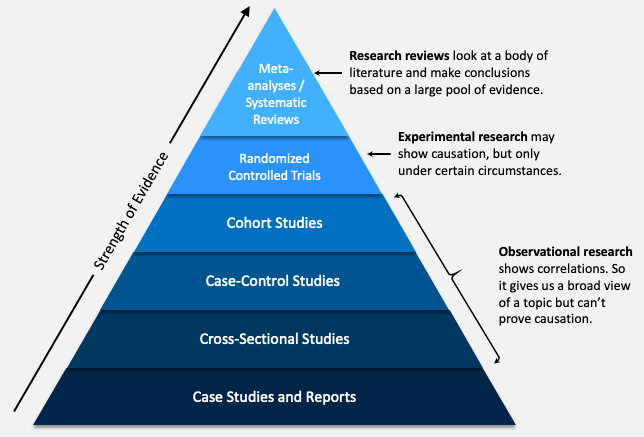

Рандомизированное контролируемое испытание (РКИ) — это форма научного эксперимента, разработанная для контроля факторов, которые не находятся под прямым экспериментальным управлением. В контексте клинических исследований, РКИ обычно сравнивает новое лечение с существующим стандартом или плацебо. В A/B-тестировании это могут быть две разные версии одной страницы (например, "А" и "Б"), два разных алгоритма выдачи товаров, или даже различные подходы к ценообразованию.

**Ключевая идея РКИ заключается в случайном распределении участников** (в нашем случае — пользователей) по различным группам, получающим разные воздействия. Этот процесс рандомизации позволяет достичь **статистического контроля** над известными и неизвестными факторами, которые могут влиять на результаты, но не могут быть напрямую контролируемы. Например, пользователи торговой площадки вроде Ozon или Wildberries сильно различаются по покупательской способности, предпочтениям, техническим навыкам и множеству других параметров. Без рандомизации невозможно было бы отделить эффект нового дизайна кнопки от влияния того, что пользователи с определенными характеристиками чаще попадали в группу с новым дизайном.

Именно благодаря способности минимизировать **смещение выбора (selection bias)** и **смещение распределения (allocation bias)**, а также балансировать известные и неизвестные прогностические факторы, РКИ считается **золотым стандартом** испытаний. В клинических исследованиях к этому добавляется **ослепление (blinding)**, когда участники, исследователи и аналитики не знают, к какой группе отнесены те или иные испытуемые, что снижает другие формы предвзятости. В A/B-тестировании это также реализуется, когда пользователи не знают, какую версию сайта или функции они видят.

В различных иерархиях доказательности РКИ и их систематические обзоры занимают наивысшие позиции:
*   Согласно **Guyatt и Sackett (1995)**, систематические обзоры и мета-анализы РКИ с окончательными результатами, а также сами РКИ с окончательными результатами, стоят на вершине.
*   **Оксфордский центр доказательной медицины (2009, 2011)** также помещает систематические обзоры рандомизированных контролируемых исследований (с однородностью результатов) и отдельные РКИ (с узким доверительным интервалом) на верхние уровни (1a и 1b соответственно).
*   Подход **GRADE (Grading of Recommendations Assessment, Development and Evaluation)**, используемый более чем 100 организациями, включая Всемирную организацию здравоохранения, оценивает высокое качество доказательств как "высокое", если есть большая уверенность в том, что истинный эффект близок к предполагаемому. Рандомизированные испытания без существенных ограничений считаются высококачественными доказательствами.

**Почему РКИ превосходит наблюдательные исследования**

Основное преимущество РКИ перед **наблюдательными исследованиями (observational studies)** заключается в его способности устанавливать **причинно-следственные связи**, а не просто корреляции. В наблюдательных исследованиях, как следует из названия, исследователи лишь наблюдают за происходящими событиями, не вмешиваясь в них. Это создает значительные трудности в определении, что именно вызвало наблюдаемый эффект, поскольку результаты могут быть искажены **смешивающими факторами (confounding variables)**.

Представьте, что вы анализируете данные Wildberries и видите, что пользователи, которые посещают страницы с "трендовыми" товарами, совершают больше покупок. Является ли это следствием того, что "трендовые" товары сами по себе стимулируют покупки, или же дело в том, что более активные и мотивированные покупатели склонны искать именно такие товары? В наблюдательном исследовании отделить одно от другого крайне сложно.

**Пример из электронной коммерции**

Вернемся к Wildberries. Если бы мы просто наблюдали, что пользователи, которым показывается новый, яркий баннер о скидках, покупают больше, чем те, кому он не показывается, это было бы наблюдательным исследованием. Мы не могли бы быть уверены, что именно баннер стал причиной увеличения продаж. Возможно, пользователи, которые видели баннер, были более активными и уже готовы были к покупке.
В A/B-тесте мы делаем иначе:
1.  **Случайно делим пользователей на две группы:** контрольную (А) и экспериментальную (Б).
2.  **Группе А показываем стандартный интерфейс (без нового баннера).**
3.  **Группе Б показываем интерфейс с новым баннером.**
4.  **Сравниваем ключевые метрики** (например, конверсию в покупку) между этими группами.

Благодаря рандомизации, единственное систематическое различие между группами — это наличие или отсутствие баннера. Любые другие различия (демография, история покупок, активность) будут равномерно распределены между группами случайным образом. Таким образом, если мы видим статистически значимое различие в конверсии, мы можем с высокой степенью уверенности заявить, что именно баннер **вызвал** это изменение. Это и есть **"золотой стандарт"**.

Несмотря на то, что некоторые исследования 2000-х годов предполагали, что наблюдательные исследования могут давать схожие результаты с РКИ, более поздние мета-анализы указывают на то, что **расхождения могут возникать, и различия в предполагаемой величине эффекта очень распространены**. РКИ предоставляют **убедительные доказательства того, что изучаемое воздействие вызывает эффект на поведение пользователей или на бизнес-метрики**.

**Ограничения на практике**

Несмотря на все свои преимущества, РКИ, или A/B-тесты, не лишены недостатков и ограничений, особенно при их применении в сложной динамичной среде. Критический взгляд на методологию позволяет применять РКИ более осознанно и эффективно:

1.  **Время и затраты**

Проведение РКИ может быть дорогим и трудоёмким. В медицине испытания занимают годы, в продуктовых A/B-тестах обычно недели, но и это немало: в быстро меняющемся мире, где продукты развиваются еженедельно, длительные тесты могут означать упущенные возможности или даже устаревание тестируемой гипотезы. Для оценки редких событий (например, отток очень специфического сегмента пользователей) или незначительных побочных эффектов (негативных реакций на изменение) требуются крайне большие выборки, что делает РКИ непрактичными и вынуждает прибегать к наблюдательным исследованиям.

2.  **Конфликт интересов**

Как показывают исследования, финансирование РКИ коммерческими организациями (например, производителями лекарств в медицине или крупными компаниями в IT) может быть связано с более частыми "положительными" для спонсора результатами. Это может быть обусловлено предвзятостью публикаций (publication bias), когда положительные результаты с большей вероятностью доходят до публикации. В контексте A/B-тестов это может проявляться в "подгонке" тестов под желаемый результат или остановке тестов, которые демонстрируют негативные тенденции, что ставит под вопрос объективность выводов.

3.  **Этические дилеммы**

В A/B-тестировании этические вопросы тоже возникают, хотя и не столь драматично, как в медицинских испытаниях. В медицине известно **«терапевтическое заблуждение» (therapeutic misconception)**: участники считают, что обязательно получают наилучшее для себя лечение. В A/B-тестах пользователи обычно вообще не знают об эксперименте, поэтому ответственность целиком лежит на команде. Если мы тестируем новую функцию, которая потенциально может ухудшить пользовательский опыт или привести к финансовым потерям для пользователя (например, новая модель ценообразования), этично ли сознательно подвергать часть аудитории этому риску? В случае, если инновация оказывается явно вредоносной, этические соображения могут вынудить досрочно прекратить тест, что делает невозможным получение полной картины ее влияния.

4.  **Проблемы с генерализуемостью (внешней валидностью)**

РКИ, особенно те, что тщательно контролируются (т.н. "объяснительные" или "explanatory" РКИ), проверяют эффективность в идеальных условиях с тщательно отобранными участниками. Это может ограничивать применимость их выводов к реальным, менее контролируемым условиям и более разнообразным группам пользователей. Прагматические РКИ (pRCTs) стремятся тестировать эффективность в повседневной практике, но это усложняет дизайн и анализ. Тест, проведенный на сегменте русскоязычных пользователей в Москве, может не дать тех же результатов при запуске для англоязычной аудитории в Нью-Йорке.

5.  **Методологические критические замечания**

Существуют критические замечания относительно того, что не все исследовательские вопросы могут быть адекватно решены с помощью РКИ из-за практических или этических проблем. Также, РКИ, особенно те, что фокусируются на "среднем эффекте" лечения, могут не учитывать **внутригрупповую изменчивость** — то есть, почему одни пользователи реагируют на изменение одним образом, а другие — совсем иначе.

6.  **Сетевые эффекты и "загрязнение"**

В сложных экосистемах, например платформах электронной коммерции, могут возникать **сетевые эффекты**. Это означает, что изменение, введенное для одной группы пользователей, может косвенно повлиять на другую группу, даже если она находится в контроле. Например, если мы тестируем новый алгоритм ранжирования товаров для покупателей, который приводит к резкому росту продаж у определенных продавцов, это может изменить поведение других продавцов (например, они начнут снижать цены), что в свою очередь повлияет на покупателей в контрольной группе. В таких случаях чистое разделение на "контроль" и "эксперимент" нарушается, и интерпретация результатов РКИ становится значительно сложнее. Игнорирование сетевых эффектов может привести к некорректным выводам о причинно-следственных связях.

Несмотря на эти ограничения, **РКИ остаются самым надежным инструментом для установления причинно-следственных связей**. Критический анализ этих ограничений позволяет нам, аналитикам, более осознанно подходить к дизайну экспериментов, интерпретации их результатов и принятию решений, понимая не только силу метода, но и его границы.

## Пайплайн тестирования гипотез

Эффективное научное исследование требует тщательно формализованного подхода. Этот процесс включает в себя ряд последовательных шагов, от первоначальной гипотезы до окончательного внедрения результатов, и предполагает сложную систему взаимодействия между различными командами.

В общем случае тестирование представляет из себя следующую цепочку событий:

```
1. Формулирование гипотезы
2. Прототипирование дизайна тестирования
3. Сбор данных
4. Анализ данных
5. Формулирование итогов гипотезы
6. Подтверждение/Опровержение тестируемой гипотезы
7. Внедрение/ Отказ от внедрения
```

1.  **Формулирование гипотезы**

Начальный этап любого исследования – это формулировка проверяемой гипотезы. Гипотеза должна быть максимально точно сформулирована, чтобы не вносить недопонимание в трактовке другим командам, которые также участвуют в процессе тестирования. Как минимум гипотеза должна содержать:

* Контекст, почему хотим вносить изменение
* Вносимое изменение
* Целевая аудитория
* Ожидаемый эффект

Например,

* `Контекст`: На странице карточки товара Wildberries показывает динамику цены.
Сейчас там отображается средняя цена без учёта скидок кошелька, доставки и скидок по привилегии.
Тем не менее, Wildberries имеет СПП - скидка со стороны платформы, которая не учитывается в цене.
Как итог может быть ситуация, что на этой неделе скидка уменьшилась -> цены будут выше (при прочих равных),
что негативно скажется на ощущениях пользователя (хотя продавец цены не поднимал фактически и не виноват в этом).
* `Изменение`: Будем в динамике указывать чистую цену, выставленную продавцом
* `Целевая аудитория`: Все пользователи площадки WB
* `Ожидаемый эффект`: Более справедливое отображение цены увеличит конверсию в заказ,
  т.к. не будет неоправданных завышений в динамике

2.  **Дизайн исследования**

После формулировки гипотезы разрабатывается дизайн исследования, который является критически важным для минимизации систематической ошибки и обеспечения внутренней валидности результатов. На этом этапе досконально продумывается, как будет тестироваться выдвинутая гипотеза: выбирается метод тестирования, список метрик, статистический критерий, задаются минимальные статистические параметры теста.

Например,

* `Метод тестирования`: A/B тест
* `Метрики` : конверсия из просмотра в заказ при просмотре динамики цены
* `Статистический критерий`: t-test с применением дельта метода
* `Параметры теста`:
  * `ошибка 1 рода`: 5%
  * `ошибка 2 рода`: 20%
  * `MDE`: минимальный эффект, который хотим обнаружить, например +1% к конверсии
  * `размер выборки и длительность`: считаются из параметров выше

3.  **Сбор данных**

На этапе сбора данных реализуется разработанный дизайн. Это включает в себя набор участников, их распределение по группам согласно процедурам рандомизации и сокрытия распределения, а также проведение вмешательств и измерение исходов в соответствии с протоколом. Важно обеспечивать **единообразие воздействия** (treatment fidelity: все пользователи группы получают одно и то же изменение), контролировать уровень пропущенных данных и отсева участников, а также учитывать потенциально мешающие переменные.

4.  **Анализ данных**

После сбора данных следует этап их анализа для проверки гипотезы. Здесь важно предобработать данные и верно обсчитать метрики.

5.  **Формулирование итогов гипотезы**

После предобработки данных и получения итоговых метрик необходимо их правильно провалидировать с учётом возможных ошибок, которые были заложены в дизайн теста. Итогом в идеальном случае должен быть отчёт с метриками тестовой и контрольной групп и вывод на основе статистического критерия.

6. **Подтверждение/Опровержение тестируемой гипотезы**

На основе отчёта из предыдущего шага команда аналитики выносит вердикт, подтверждается гипотеза или нет.

7. **Внедрение/ Отказ от внедрения**

В зависимости от успеха проведенного исследования уже решается, будет ли фича 'катиться в прод' или необходимо её пересмотреть с учётом недостатков, выявленных при помощи эксперимента.

Так как исследование — комплексный процесс, в нём участвуют сразу несколько команд, каждая из которых отвечает за свою составляющую. В общем виде взаимодействие может выглядеть следующим образом:

*   **Продуктовая команда:** Инициирует гипотезы, исходя из потребностей пользователей, бизнес-целей или наблюдаемых проблем. Определяет, какое изменение или новая функция может улучшить ключевые метрики.
*   **Аналитическая команда:** Формализует гипотезы в измеряемые параметры. Совместно с продуктовой командой разрабатывает дизайн эксперимента, определяет необходимые метрики, рассчитывает размер выборки и планирует методы анализа данных. Также обеспечивает прозрачность и точность результатов.
*   **Команда разработки:** Реализует техническую часть эксперимента. Это может включать разработку новых функций, механизмов рандомизации пользователей, инструментов сбора данных и интеграцию с аналитическими системами. Обеспечивает техническую возможность проведения эксперимента в соответствии с дизайном.

Дальше работает итерационный цикл: после сбора данных аналитики проводят анализ, результаты которого возвращаются продуктовой команде для принятия решений о дальнейшем развитии продукта. Этот цикл повторяется, создавая культуру принятия решений, основанных на данных.

## Виды тестов

Тесты можно поделить по основным 3 критериям:
  1. **Цель тестирования** - что хотим проверить
  2. **Направленность альтернативной гипотезы** - эффект в какую сторону хотим смотреть
  3. **Стратегия проведения** - как рассчитывается тест

### Цель тестирования  

1. **Superiority Tests (тест на превосходство)**

Тесты на превосходство — это односторонние проверки гипотез, в которых нулевая и альтернативные гипотезы сформулированы так, чтобы можно было проверить, превосходит ли одна группа другую более чем на заданный предел. Таким образом, нам может быть интересно показать, что новый алгоритм ранжирования рекомендаций превосходит другой более чем на незначимую для бизнеса величину.

**Цель**: доказать, что новое средство (алгоритм, препарат, дизайн) статистически лучше эталонного минимум на заданную величину.

**Формулировка:**

$$
\begin{equation}
    \begin{cases}
      H_0: \mu_{new} - \mu_{ref} \le \delta\\
      H_1: \mu_{new} - \mu_{ref} > \delta
    \end{cases}
\end{equation}
$$

**Примеры:**
* A/B-тест: новый дизайн сайта vs старый. μ = конверсия.
* Клиническое: новая вакцина дает более высокий средний уровень антител.
* Алгоритм рекомендательной системы демонстрирует большую среднюю глубину сессии.

2. **Non-inferiority Tests (тест не меньшей эффективности)**

Тесты не меньшей эффективности - это односторонние проверки гипотез, в которых нулевая и альтернативные гипотезы выстраиваются так, чтобы проверить, является ли одна группа почти такой же хорошей (не намного хуже), чем другая. Например, нам может быть интересно показать, что новый, менее затратный метод работы бэкенда (например который хранит меньше кэша) не хуже существующего.

**Цель:** доказать, что новое решение не уступает старому более, чем на заранее заданную «не-худшую» границу $\delta > 0$.

**Формулировка:**

$$
\begin{equation}
    \begin{cases}
      H_0: \mu_{new} - \mu_{ref} \le -\delta \\
      H_1: \mu_{new} - \mu_{ref} > -\delta
    \end{cases}
\end{equation}
$$

**Примеры:**  

* Новый дженерик-препарат по эффективности «не хуже» оригинала более чем на $\delta$=10%.
* Обновлённый компрессор в промышленной установке должен работать «не хуже» текущего по выходной мощности ($\delta$ = 5 кВт).
* Новая версия мобильного приложения должна загружать страницы не более чем на $\delta$ = 200 мс дольше текущей.

3. **Equivalence Tests (тест на эквивалентность)**  

Тесты эквивалентности используются для убедительного доказательства эквивалентности двух методов. Традиционный метод проверки гипотез эквивалентности заключается в проведении двух односторонних тестов (TOST). Нулевая гипотеза о неэквивалентности отвергается в пользу альтернативной гипотезы об эквивалентности, если отвергаются оба односторонних теста. Однако, в отличие от обычных двухсторонних тестов, частота ошибок первого рода устанавливается непосредственно на номинальном уровне (обычно 0,05) — она не делится пополам. Таким образом, для проведения теста проводятся два односторонних теста на уровне значимости α. Если оба теста отвергаются, альтернативная гипотеза подтверждается на уровне значимости α. Обратите внимание, что p-значение теста — это максимальное из p-значений двух тестов.

**Цель:** показать, что разница между новинкой и референсом лежит внутри предопределённого интервала (–$\delta$, +$\delta$).

**Формулировка:**

$$
\begin{equation}
    \begin{cases}
      H_0: \left(\mu_{new} - \mu_{ref} \le -\delta \right) \cup \left(\mu_{new} - \mu_{ref} \ge +\delta \right) \\
      H_1: -\delta < \mu_{new} - \mu_{ref} < +\delta
    \end{cases}
\end{equation}
$$

**Примеры:**  

* Два способа измерения давления: нужно доказать, что их показания эквивалентны в ±3 мм рт. ст.
* Алгоритм сжатия нового формата видео даёт качество, эквивалентное старому в пределах ±2 % PSNR.
* Пилотный сайт-клон должен давать эквивалентную конверсию в пределах ±0.5 %.

4. **Futility Tests (тест на бесперспективность)**  

**Цель:** на промежуточном этапе остановить «безнадёжный» эксперимент, если достижение клинически/бизнес-значимого эффекта маловероятно.

**Формулировка:**

$$
\begin{equation}
    \begin{cases}
      H_0:  \text{effect} \ge \Delta_{min}  \\
      H_1: \text{effect} < \Delta_{min}
    \end{cases}
\end{equation}
$$

**Примеры:**  

* Фарма-исследование: на 50% набора пациентов препарат не показывает обещанного улучшения — прекращаем.
* A/B-тест: на половине трафика новая функция вовсе не повышает конверсию к порогу +2 % → останавливаем запуск.
* Инженерный пилот: новый двигатель не достигает требуемой мощности $\Delta_{min}$ = 100 кВт при 75% испытаний — закрываем проект.

___

Вот визуализация, показывающая разницу между первыми тремя видами тестов:

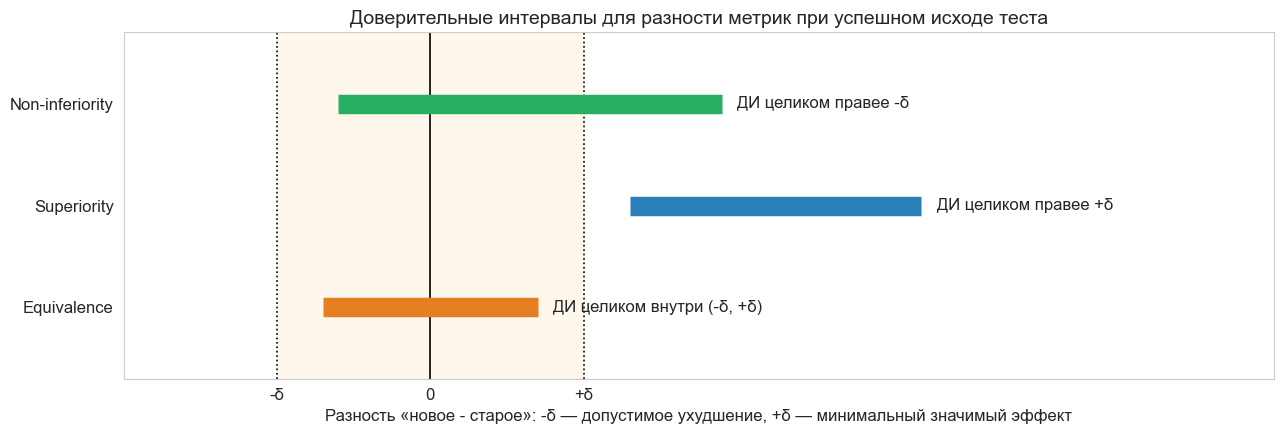

In [2]:
# Примеры доверительных интервалов для разности «новое - старое» при успешном исходе теста
margin = 1.0
examples = [
    ('Equivalence', (-0.7, 0.7), '#e67e22', 'ДИ целиком внутри (-δ, +δ)'),
    ('Superiority', (1.3, 3.2), '#2980b9', 'ДИ целиком правее +δ'),
    ('Non-inferiority', (-0.6, 1.9), '#27ae60', 'ДИ целиком правее -δ'),
]

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.axvspan(-margin, margin, color='#f39c12', alpha=0.08)
for x in (-margin, 0, margin):
    ax.axvline(x, color='black', linestyle=':' if x else '-', linewidth=1.2)
for row, (name, (left, right), color, note) in enumerate(examples):
    ax.plot([left, right], [row, row], color=color, linewidth=14, solid_capstyle='butt')
    ax.text(right + 0.1, row, note, va='center', fontsize=12)
ax.set_yticks(range(3), labels=[e[0] for e in examples])
ax.set_xticks([-margin, 0, margin], labels=['-δ', '0', '+δ'])
ax.set_xlabel('Разность «новое - старое»: -δ — допустимое ухудшение, +δ — минимальный значимый эффект')
ax.set_xlim(-2, 5.5)
ax.set_ylim(-0.7, 2.7)
ax.grid(False)
ax.set_title('Доверительные интервалы для разности метрик при успешном исходе теста', fontsize=14)
plt.tight_layout()
plt.show()

### Направленность альтернативной гипотезы

1. **Односторонние тесты (One-sided)**

Это статистические тесты, в которых альтернативная гипотеза предполагает, что параметр больше или меньше определенного значения, то есть использует знак «<» или «>». Соответственно в зависимости от направленности эффекта бывает как **левосторонний (left-tailed)**, так и **правосторонний (right-tailed)**.

Их нужно применять, когда
* Интересует только одна сторона отклонения — например, только увеличение или только уменьшение.
* Решение не изменится, если эффект окажется в другую сторону.

Направление выбирается **до** начала теста. Выбирать его после того, как увидели данные, нельзя: фактический уровень значимости удвоится.

Примеры:

1. Проверка, что новый препарат эффективнее стандартного

$$
\begin{equation}
    \begin{cases}
      H_0: \mu_{new} \leq \mu_{stand} \\
      H_1: \mu_{new} > \mu_{stand}
    \end{cases}
\end{equation}
$$

2. Проверка, что новое устройство работает быстрее старого

$$
\begin{equation}
    \begin{cases}
      H_0: \text{time}_{new} \geq \text{time}_{stand} \\
      H_1: \text{time}_{new} < \text{time}_{stand}
    \end{cases}
\end{equation}
$$

3. Проверка, что уровень удовлетворенности клиентов повысился

$$
\begin{equation}
    \begin{cases}
      H_0: \text{satisfaction}_{new} \leq \text{satisfaction}_{stand} \\
      H_1: \text{satisfaction}_{new} > \text{satisfaction}_{stand}
    \end{cases}
\end{equation}
$$

2. **Двухсторонние тесты (Two-sided)**

Это тесты, в которых альтернативная гипотеза утверждает, что параметр не равен определенному значению, то есть использует знак «≠».

Их нужно применять, когда
* Важно определить, есть ли различие в любую сторону — увеличение или уменьшение.
* Эффект может проявляться в обе стороны и нужно проверить наличие различия в целом.

Примеры:

1. Проверка, отличается ли среднее значение от заданного уровня:

$$
\begin{equation}
    \begin{cases}
      H_0: \mu = \mu_0 \\
      H_1: \mu \neq \mu_0
    \end{cases}
\end{equation}
$$

2. Проверка, есть ли разница между двумя методами лечения:

$$
\begin{equation}
    \begin{cases}
      H_0: \mu_1 = \mu_2 \\
      H_1: \mu_1 \neq \mu_2
    \end{cases}
\end{equation}
$$

3. Проверка, отличается ли уровень холестерина после диеты от исходного:

$$
\begin{equation}
    \begin{cases}
      H_0: \text{level}_{new} = \text{level}_{stand} \\
      H_1: \text{level}_{new} \neq \text{level}_{stand}
    \end{cases}
\end{equation}
$$

___

Визуально разница между этими тестами выражается в критической зоне распределения статистики:

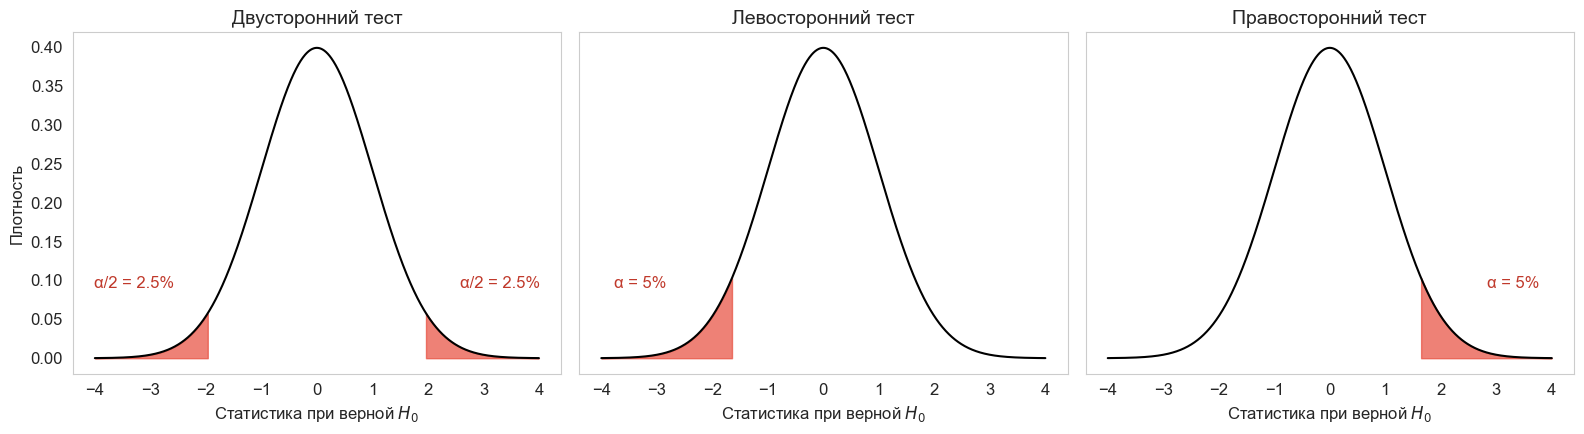

In [3]:
alpha = 0.05
x = np.linspace(-4, 4, 1_000)
pdf = stats.norm.pdf(x)
z_two, z_one = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(1 - alpha)

zones = [
    ('Двусторонний тест', [(x <= -z_two, 'α/2 = 2.5%', -3.3), (x >= z_two, 'α/2 = 2.5%', 3.3)]),
    ('Левосторонний тест', [(x <= -z_one, 'α = 5%', -3.3)]),
    ('Правосторонний тест', [(x >= z_one, 'α = 5%', 3.3)]),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (title, areas) in zip(axes, zones):
    ax.plot(x, pdf, color='black')
    for mask, label, x_text in areas:
        ax.fill_between(x[mask], pdf[mask], color='#e74c3c', alpha=0.7)
        ax.text(x_text, 0.09, label, ha='center', fontsize=12, color='#c0392b')
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Статистика при верной $H_0$')
    ax.grid(False)
axes[0].set_ylabel('Плотность')
plt.tight_layout()
plt.show()

### Стратегия проведения

1. **Фиксированный План (Fixed-Horizon Design)**

**Что это:** Классический, самый простой дизайн. Все параметры испытания (размер выборки, точки анализа, первичные конечные точки) фиксируются до начала набора выборки и не меняются в процессе исследования. Анализ данных проводится только один раз – после того, как будет достигнут запланированный объём выборки и будут собраны все данные.

**Зачем нужен:** Простота планирования, проведения, анализа и регуляторного одобрения. Минимизация риска предвзятости из-за множественных проверок данных. Прямая интерпретация результатов.

**Основные методы**:
* $t$-test
* $z$-test
* $\chi^2$-test
* Fisher-exact test
...

**Когда лучше применять:**

* Когда ресурсы (время, деньги) позволяют набрать сразу всю большую выборку.
* Когда риски хорошо изучены, и нет острой этической необходимости в досрочной остановке.
* Когда требуется максимальная простота и прозрачность для регуляторов.

**Примеры:**

1. Изменение цвета/текста кнопки CTA: Тест новой кнопки "Купить" (зеленая vs синяя, "Добавить в корзину" vs "Купить сейчас") на странице товара. Размер выборки рассчитан на ожидаемое изменение конверсии в корзину/покупку. Анализ – строго через 2 недели.

2. Внедрение новой формы быстрой оплаты: Сравнение конверсии на этапе оплаты между старой многошаговой формой и новой упрощенной (например, через 1 клик). Тест длится фиксированные 3 недели, анализ только в конце по метрике "успешные оплаты".

3. Изменение лимита на бесплатную доставку или минимальной суммы для cashback: Тест влияния повышения/понижения порога на средний чек или активность. Параметры фиксированы, анализ – после сбора данных за квартал.

2. **Последовательные Тесты (Sequential Designs)**

**Что это:** Дизайны, в которых данные анализируются неоднократно по мере поступления (например, после набора каждых 50, 100, 150 пациентов или через определенные промежутки времени). Позволяют досрочно остановить исследование из-за явной эффективности, явной неэффективности или неприемлемого вреда до набора полной выборки.

**Зачем нужен:**
  * **Этическая выгода:** Прекращение испытания, если лечение явно эффективно (чтобы быстрее дать его всем) или явно вредно/неэффективно (чтобы не подвергать пациентов риску без пользы).
  * **Экономическая выгода:** Экономия времени и ресурсов при досрочной остановке. Особенно актуально для долгих или дорогих исследований (например, с выживаемостью как конечной точкой).

**Основные методы (ключевые концепции):**

* SPRT и mSPRT - Sequential Probability Ratio Test и его вариант mixture SPRT
* AVI - Always Valid Inference
* GST - Group Sequential Testing
...

**Когда лучше применять:**

* Когда конечная точка является "ценной" (выживаемость, тяжелые события) и есть этический императив минимизировать воздействие неэффективного/вредного лечения или быстро внедрить эффективное.

* Когда исследование очень длительное или дорогостоящее, и досрочная остановка дает значительную экономию.

* Когда исходный эффект не вполне ясен, и есть значительная неопределенность.

* Когда размер требуемой выборки очень велик.

**Примеры:**

1. Тест новой программы лояльности: Промежуточные анализы запланированы через 1, 2 и 3 месяца. Метрики: LTV (Lifetime Value), retention rate, частота покупок/операций. Если через 1 месяц видно значимое падение LTV у новой группы, тест останавливают досрочно, чтобы минимизировать убытки. Если виден явный рост – можно ускорить rollout.

2. Тест новой скоринговой модели для кредита/овердрафта: Анализы после обработки каждых 1000 заявок. Ключевые метрики: одобрение/отказ, процент просрочек (delinquency rate). Если на промежуточном анализе просрочки в тестовой группе значительно выше контрольной, тест останавливают досрочно из-за неприемлемого риска. Если одобрение значительно выше без роста риска – можно внедрять быстрее.

3. Тест нового алгоритма детекции мошенничеств: Промежуточные анализы после выявления каждых 50 подтвержденных случаев мошенничества. Метрики: точность (precision), полнота (recall), % ложных срабатываний (false positive rate). Если на раннем анализе FPR неприемлемо высок (слишком много легитимных транзакций блокируется), тест останавливают для доработки модели. Если точность и полнота резко улучшились без роста FPR – алгоритм внедряют.

3. **Адаптивные Тесты (Adaptive Designs)**

**Что это:** Наиболее гибкий тип дизайнов. Позволяют заранее запланировать модификацию параметров исследования на основе промежуточных данных (обычно "слепых" по воздействию, чтобы минимизировать предвзятость). Модификации основаны на предопределенных правилах и требуют строгого статистического контроля.

**Зачем нужен:**

  * **Повышение гибкости и эффективности:** Возможность реагировать на информацию, полученную в ходе исследования, для оптимизации дизайна.
  * **Этическая и экономическая выгода:** Более быстрая идентификация лучших доз/групп, прекращение бесперспективных ветвей, корректировка размера выборки под реальную изменчивость/эффект.

**Основные методы (ключевые концепции):**

* Адаптация размера выборки (Sample Size Re-Estimation - SSR): Увеличение или уменьшение общего числа участников на основе промежуточных оценок эффекта или вариабельности данных.

* Адаптация дизайна (Adaptive Seamless Designs): Объединение фаз (напр., IIb и III) в одно исследование. На раннем этапе выбираются перспективные дозы/группы для продолжения на позднем этапе с большей выборкой.

* Переключение первичной конечной точки: Изменение главной измеряемой переменной (с заранее оговоренных альтернатив) на основе промежуточных данных (редко, требует крайне осторожного подхода).

* Популяционная адаптация (Adaptive Enrichment): Сужение или изменение критериев включения (напр., пользователей с определенным параметром) на основе промежуточных данных для фокусировки на подгруппе, где наиболее вероятно будет эффект.

* Байесовские адаптивные дизайны: Используют байесовскую статистику для непрерывного обновления вероятности успеха по мере поступления данных и принятия адаптивных решений.

**Когда лучше применять:**

* Когда высокая неопределенность в ключевых параметрах (размер эффекта, вариабельность).

* Когда нужно оптимизировать дозу или выбрать лучшую из нескольких экспериментальных групп эффективно.

* Когда исследуется болезнь с неоднородным ответом (напр., онкология с биомаркерами), и нужно сфокусироваться на респондерах.

* Когда ресурсы ограничены, и требуется максимальная "отдача" от исследования.

* Когда разработка должна быть ускорена (напр., для заболеваний с высокой неудовлетворенной потребностью).

**Примеры:**

1. Адаптивное многорукое тестирование (Multi-Armed Bandit - MAB) для рекламных креативов или промо-предложений: Тест 5 разных баннеров на главной странице. Алгоритм динамически перераспределяет трафик в пользу вариантов, показывающих лучшую CTR (или конверсию) на ранних этапах. Менее эффективные варианты постепенно получают меньше трафика. Цель – максимизировать общую эффективность во время теста.

2. Адаптация размера выборки (SSR) для сложной метрики: Тест нового дизайна каталога товаров. Первичная метрика – конверсия в покупку с глубиной просмотра >5 страниц (редкое событие). На промежуточном анализе (через 1 неделю) оценивается реальная вариабельность и наблюдаемый эффект. Если эффект слабее ожидаемого, размер выборки автоматически увеличивается по предопределенному правилу, чтобы сохранить мощность теста к концу.

3. Адаптивное обогащение / таргетирование: Тест персонализированной скидки. Изначально тест запущен для всей аудитории. Промежуточный анализ выявляет, что предложение особенно эффективно для пользователей с высокой исторической частотой покупок. По предопределенному правилу фокус теста смещается (увеличивается доля трафика для этой группы), чтобы точнее оценить эффект и быстрее принять решение о внедрении для целевой подгруппы.

___

**Сводная Таблица для Сравнения**

| Характеристика | Фиксированный план | Последовательный дизайн | Адаптивный дизайн |
| --- | --- | --- | --- |
| **Основная черта** | Все параметры фиксированы заранее | Множественные анализы, возможность досрочной остановки | Изменение параметров на основе данных |
| **Кол-во анализов** | Один (в конце) | Несколько (заранее запланированных) | Один или несколько + модификация дизайна |
| **Главная цель**| Простота, доказательство гипотезы | Этическая/экономическая остановка | Гибкость, эффективность, ускорение |
| **Сложность** | Низкая | Умеренная | Высокая |
| **Стат. контроль** | Относительно простой | Динамические границы ошибок 1 и 2 рода | Сложные методы (комбинация тестов, Байес) |
|**Лучше всего для**| Предсказуемые эффекты, короткие исследования, простота | Дорогие и длительные исследования, этически чувствительные конечные точки | Высокая неопределенность, оптимизация доз/популяций, ускорение|

## Формализация A/B тестирования

Процесс формализации A/B-тестирования представляет собой систематический подход для оценки эффективности изменений, основанный на статистическом анализе. Он позволяет принимать математически обоснованные решения о внедрении новых функций или доработок.

Пайплайн A/B-тестирования включает в себя несколько ключевых этапов:
1. **Постановка гипотез (Нулевая $H_0$ и Альтернативная $H_1$)**

    В основе любого A/B-теста лежит проверка статистических гипотез:

    * **Нулевая гипотеза $H_0$** - это утверждение об отсутствии эффекта от тестируемого изменения. Например, $H_0$ может гласить, что среднее значение метрики в тестовой группе (T) равно среднему значению в контрольной группе (C), то есть $\mu_t = \mu_c$. Или, в абсолютной постановке, разница средних равна нулю: $\mu_t - \mu_c = 0$.

      **Это гипотеза, которую мы стремимся опровергнуть.**

    * **Альтернативная гипотеза $H_1$** - это утверждение о наличии эффекта или различии между тестовой и контрольной группами. Например, $H_1$ может утверждать, что $\mu_t \neq \mu_c$ (двухсторонняя гипотеза), или $\mu_t > \mu_c$ (односторонняя гипотеза), или что отношение $(\mu_t - \mu_c) / \mu_c \neq 0$ для относительного эффекта.
      
      **Это то, что мы хотим подтвердить.**

    Чёткая формулировка гипотез критически важна, поскольку она определяет, что именно мы измеряем и какие выводы сможем сделать. Использование как абсолютных, так и относительных метрик для постановки гипотез повышает наглядность и интерпретируемость результатов для бизнеса.

2. **Определение уровней ошибок первого ($\alpha$) и второго ($\beta$) рода**

    Определение этих уровней ошибок позволяет контролировать риск неверного решения. Это баланс между риском внедрить неэффективное изменение и риском пропустить потенциально полезное. Подробнее их смотрим чуть позже.

3. **Выбор подходящего статистического критерия**

    После формулировки гипотез и определения уровней ошибок необходимо выбрать статистический критерий, который будет использоваться для проверки гипотез. Подробнее их рассмотрим далее, но общий принцип - выбираем такой критерий, который:
    1. подходит под распределение данных - у критериев есть свои предпосылки, которые не должны нарушаться;
    2. на данных выдаёт ошибки первого и второго рода в рамках номинальных (установленных в шаге 2);
    3. по возможности является самым мощным из всех возможных альтернатив.

4. **Расчет размера выборки**

    После формулировки гипотез, определения уровней ошибок и выбора статистического критерия, который будет использоваться для проверки гипотез, надо определить необходимый размер выборки. Размер напрямую зависит от того, насколько большие или маленькие эффекты мы хотим уметь детектировать. Подробнее об этом будет рассказано далее.

5. **Расчет статистики на данных**

    После сбора данных, метрики для контрольной и тестовой групп вычисляются, и на их основе рассчитывается статистическая значимость. Это включает:
    1. Вычисление точечных оценок метрик (например, средних) для каждой группы.
    2. Расчет разницы или отношения метрик между группами.
    3. Вычисление тестовой статистики и соответствующего p-value.
    4. Построение доверительных интервалов для оценки эффекта.

6. **Анализ результатов и принятие решения**

    На этом этапе анализируются p-value и доверительные интервалы для решения, отвергать ли нулевую гипотезу.

    * Использование p-value:
        * Если p-value меньше установленного уровня значимости ($\alpha$), то нулевая гипотеза отклоняется, и делается вывод о наличии статистически значимого эффекта.
    * Использование доверительных интервалов:
        * Если ноль не попадает в доверительный интервал для разницы метрик, это эквивалентно отклонению нулевой гипотезы и означает наличие статистически значимого эффекта.
        * Доверительные интервалы предпочтительнее p-value для интерпретации результатов, так как они дают не только информацию о наличии эффекта, но и о его численной величине и точности (например, "+10±5М рублей").
    * Интерпретация "серых" (не статистически значимых) результатов:
        * Даже если результат не является статистически значимым, доверительный интервал может дать ценные инсайты. Например, он позволяет понять, какой максимальный эффект мог бы быть, если бы он действительно существовал, или наоборот, исключить слишком большие эффекты.
        * Важно не просто констатировать отсутствие эффекта, а заявлять, что "если эффект и есть, то он находится в определённых границах".

Теперь подробно с технической точки зрения рассмотрим каждый из этапов.

### Типы метрик

Когда мы сформулировали у себя в голове гипотезу, необходимо подумать, а какие метрики мы должны отслеживать, чтобы её подтвердить или опровергнуть? Одно и то же можно мерить с помощью разных метрик, но как выбрать наилучшую из них?

**Продуктовая точка зрения**

С продуктовой точки зрения нам необходимо понимать две вещи:

1. **Простота метрик**

Чем **проще** метрика для объяснения - тем лучше для вас, т.к. результаты всегда легче сообщать во всём понятных терминах (особенно хорошо управленцы почему-то понимают денежные метрики). Для примера сравните две формулировки:
  * 'Данные подтверждают гипотезу, т.к. в тестовой группе средняя продолжительность визита пользователей статистически значимо сократилась.'
  * 'Данные подтверждают гипотезу, т.к. взвешенная сумма среднего времени сессии, количества просмотренных страниц и коэффициента взаимодействия с элементами сайта статистически значимо сократилась.'

Поэтому чем метрика ближе бизнесу и легче для понимания и интерпретирования эффекта, тем более привлекательна она для выбора.

2. **Уровень прокраса**

Разные метрики **"прокрашиваются по-разному"**, то есть для разных метрик необходимо разное количество данных, чтобы получить статистически значимые отличия. Например, мы хотим померить разницу конверсий в открытии отзывов. Отзывы открывают довольно редко — скажем, базовая конверсия составляет около 0.0005 (0,05%). В таком случае, чтобы обнаружить даже небольшое увеличение этой конверсии, нам потребуется очень большой объем данных. Допустим, в тестовой группе конверсия увеличилась до 0.0007 (0,07%). Из-за очень низкой начальной конверсии для обнаружения такого эффекта при $\alpha=0.05$ и мощности 80% потребуется около 235 тысяч пользователей в каждой группе: число открытий отзывов очень мало.

В то же время, если мы измеряем изменение в более часто встречающейся метрике, например, скрол экрана до отзывов, у которых базовая конверсия составляет, скажем, 0.05 (5%), то для обнаружения такого же относительного увеличения (до 7%) хватит примерно 2.2 тысячи пользователей в группе, то есть в 100 раз меньше.

То есть чем выше **чувствительность** метрики, тем меньшая выборка нужна для обнаружения эффекта.

Чтобы понять, какая метрика более или менее чувствительна, обычно прибегают к следующим вещам:

1. анализ уже прошедших A/B тестов, где можно провалидировать, был ли прокрас метрики или нет.
2. поиск прокси-метрик (proxy metric). Это метрики, которые сильно скоррелированы с целевой метрикой и сонаправлены с ней, но при этом более чувствительны. Например, долгосрочное удержание измеряется месяцами, а активность пользователя в первую неделю видна сразу и может служить его прокси. Основная сложность в том, чтобы найти такие метрики, но Microsoft ([понятный обзор статьи](https://www.youtube.com/watch?v=fSRKOr3L6AI)) в своей статье показывают, как это сделать проще и правильнее.

**Техническая точка зрения**

С аналитической точки зрения метрики делятся по двум разрезам:

1. **Цель метрик**

Базово можно поделить метрики на 4 типа:
  * **Success** - метрики, которые хотим улучшить;
  * **Guardrail** - метрики, которые не должны упасть более чем на определённый уровень;
  * **Deterioration** - метрики, которые не должны упасть вообще;
  * **Quality** - метрики здоровья тестирования;

Зачастую типы метрик определяются типом гипотезы, которая выдвигается в тесте и будет покрываться этими метриками. Так, success метрики зачастую проверяются superiority тестами, guardrail — non-inferiority, deterioration — inferiority тесты.

Тем не менее, зачастую можно встретить A/B тесты, которые включают сразу несколько метрик.

Рассмотрим игрушечный [пример](https://arxiv.org/pdf/2402.11609) от Spotify. Пусть мы хотим провести тест нового рекомендательного алгоритма музыки, тогда мы хотим смотреть на увеличение количества минут прослушивания музыки. При этом мы хотим убедиться, что рост не происходит за счёт подкастов, поэтому смотрим и на минуты прослушивания подкастов. Обе метрики также включены как метрики ухудшения, чтобы гарантировать, что они не меняются в сторону, противоположную ожидаемой. Кроме того, как deterioration-метрика включена доля пользователей, столкнувшихся со сбоями. Единственной метрикой качества здесь является Sample Ratio Mismatch.

| Тип метрики | Наименование метрики | Тестируемое направление изменения |
| --- | --- | --- |
| **Success** | Прослушанных минут музыки | Увеличение |
| **Guardrail** | Прослушанных минут подкастов | Увеличение |
| **Deterioration** | Прослушанных минут музыки | Снижение |
| **Deterioration** | Прослушанных минут подкастов | Снижение |
| **Deterioration** | Доля юзеров с багами | Увеличение |
| **Quality**| Sample Ratio Mismatch (SRM)| N/A |

2. **Гранулярность метрик**

Это градация чисто техническая, которая необходима для правильного обсчёта статистик. Под **объектом** будем понимать то, на что направлено тестируемое действие. С одного объекта за время эксперимента можно получить много значений (например, покупатель сделает несколько покупок). Мы делим метрики на следующие типы по отношению к группировке относительно объекта:

2.1. **User-level Метрики**

  Эти метрики вычисляются для каждого уникального объекта в отдельности, а затем усредняются (или берётся медиана и т.д.) по всем объектам в группе. Значение метрики привязано к уникальному идентификатору объекта.

$$
\text{Metric}_\text{user level} = \frac{1}{N} \sum_N \text{User Metric}
$$

  Например, к таким метрикам относятся:

  * Средняя выручка на пользователя (ARPU - Average Revenue Per User): Общая выручка группы / Количество уникальных пользователей;
  * Среднее количество сессий на пользователя: Общее количество сессий / Количество уникальных пользователей;
  * Среднее время, проведенное на платформе за период (на пользователя): Общее время всех пользователей / Количество уникальных пользователей;
  * Процент платящих пользователей (Paying User Rate): (Количество пользователей с ≥1 покупкой) / Количество уникальных пользователей;
  * Среднее количество покупок на пользователя
  * Среднее время, проведенное на сайте одним пользователем

  С такими метриками мы работаем в рамках обычных статистических тестов без каких-либо изменений.

2.2. **Ratio Метрики**

  Эти метрики вычисляются как отношение количества событий одного типа к количеству событий другого типа (или к общему количеству событий) в рамках определенного периода или группы. Значение метрики не привязано напрямую к уникальному объекту; оно отражает плотность или интенсивность событий.

$$
\text{Metric}_\text{ratio} = \frac{\sum_N \text{Event A}}{\sum_N \text{Event B}}
$$

  Например, к таким метрикам относятся:

  * CTR (Click-Through Rate): Клики / Показы
  * Conversion Rate (Коэффициент конверсии): Покупки / Посещения (или Покупки / Сессии, Заявки / Просмотры товара)
  * Bounce Rate (Процент отказов): Сессии с одним событием / Все сессии
  * Средняя глубина просмотра: Просмотренные страницы / Сессии
  * Среднее время на сайте/в приложении: Общее время / Сессии

  С метриками отношений всё сложнее. Стандартные критерии предполагают независимые наблюдения (i.i.d.), а рандомизируем мы пользователей. События одного пользователя (его сессии, показы) зависимы между собой, поэтому формула дисперсии, которая считает их независимыми, занижает разброс: p-value получается заниженным, а эффекты находятся там, где их нет. Правильный подход — считать дисперсию на уровне единицы рандомизации: либо [дельта-методом](https://habr.com/ru/companies/X5Tech/articles/740476/) (практика 1.П1), либо с помощью линеаризации (занятие 1.04), либо бутстрепом по пользователям.

### Матрица ошибок (Confusion matrix), ошибки 1 и 2 рода

#### Код для демонстрации

In [4]:
def plot_error_distributions(delta: float = 2.5, se: float = 1.0, alpha: float = 0.05) -> None:
    """
    Показывает распределения статистики при H₀ и H₁ и подсвечивает ошибки I и II рода.

    Parameters
    ----------
    delta : float
        Эффект: сдвиг статистики при верной H₁.
    se : float
        Стандартная ошибка статистики.
    alpha : float
        Уровень значимости одностороннего Z-теста.
    """
    critical_value = stats.norm.ppf(1 - alpha, loc=0, scale=se)
    x_grid = np.linspace(-4 * se, delta + 4 * se, 1_000)
    pdf_null = stats.norm.pdf(x_grid, loc=0, scale=se)
    pdf_alt = stats.norm.pdf(x_grid, loc=delta, scale=se)
    beta = stats.norm.cdf(critical_value, loc=delta, scale=se)

    plt.figure(figsize=(14, 7))
    plt.plot(x_grid, pdf_null, label='$H_0$: эффекта нет', color='C0')
    plt.plot(x_grid, pdf_alt, label=f'$H_1$: эффект δ = {delta}', color='C1')
    plt.axvline(critical_value, color='k', linestyle='--', label='Критическое значение')

    mask_type_i = x_grid >= critical_value
    plt.fill_between(x_grid[mask_type_i], pdf_null[mask_type_i], color='C0', alpha=0.3,
                     label=f'Ошибка I рода: α = {alpha:.2f}')
    mask_type_ii = x_grid <= critical_value
    plt.fill_between(x_grid[mask_type_ii], pdf_alt[mask_type_ii], color='C1', alpha=0.3,
                     label=f'Ошибка II рода: β = {beta:.2f}')

    plt.title('Ошибки I и II рода в одностороннем Z-тесте')
    plt.xlabel('Значение статистики (разность средних)')
    plt.ylabel('Плотность')
    plt.legend(loc='upper right')
    plt.show()


def calculate_and_plot_mde(n: int = 1_000,
                           sigma: float = 1.0,
                           alpha: float = 0.05,
                           target_power: float = 0.8) -> float:
    """
    Строит кривую мощности одностороннего Z-теста для двух групп по n наблюдений
    и возвращает минимально обнаруживаемый эффект (MDE).
    """
    se = sigma * np.sqrt(2 / n)
    z_alpha = stats.norm.ppf(1 - alpha)
    mde = (z_alpha + stats.norm.ppf(target_power)) * se

    delta_values = np.linspace(0, 2 * mde, 500)
    power_values = stats.norm.sf(z_alpha - delta_values / se)

    plt.figure(figsize=(14, 6))
    plt.plot(delta_values, power_values, label='Мощность 1-β(δ)', color='C0')
    plt.axhline(target_power, color='k', linestyle='--', label=f'Целевая мощность = {target_power:.2f}')
    plt.axvline(mde, color='r', linestyle='--', label=f'MDE ≈ {mde:.3f}')
    plt.scatter([mde], [target_power], color='r', zorder=3)
    plt.title('Мощность одностороннего Z-теста и MDE')
    plt.xlabel('Эффект δ')
    plt.ylabel('Мощность теста')
    plt.legend()
    plt.show()

    print(f'При n={n} в группе, σ={sigma:.2f}, α={alpha:.2f} и мощности {target_power:.2f} MDE ≈ {mde:.3f}')
    return float(mde)


def plot_pvalue_cdf(ax: plt.Axes, pvalues_aa: FloatArray, pvalues_ab: FloatArray, alpha: float, title: str) -> None:
    """Рисует эмпирические функции распределения p-value в A/A и A/B и отмечает α и мощность."""
    grid = np.linspace(0, 1, 1_000)
    estimate_alpha = float(np.mean(pvalues_aa < alpha))
    estimate_power = float(np.mean(pvalues_ab < alpha))

    ax.plot(grid, np.mean(pvalues_aa[:, None] < grid, axis=0), label='A/A эксперимент', color='#3498db')
    ax.plot(grid, np.mean(pvalues_ab[:, None] < grid, axis=0), label='A/B эксперимент', color='#e74c3c')
    ax.plot([alpha, alpha], [0, 1], '--k', alpha=0.6, label='Порог α')
    ax.plot([0, alpha], [estimate_alpha, estimate_alpha], '--', color='#2980b9', label=f'Эмпирическое α = {estimate_alpha:.3f}')
    ax.plot([0, alpha], [estimate_power, estimate_power], '--', color='#c0392b', label=f'Мощность = {estimate_power:.3f}')
    ax.plot([0, 1], [0, 1], '--k', alpha=0.4)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Значение p-value')
    ax.set_ylabel('Доля p-value < x')
    ax.legend(fontsize=10)

#### Объяснение

Никакое тестирование не исключает ошибок, ведь полученный результат — одна из возможных реализаций случайности. Тем не менее статистика позволяет работать в условиях неопределённости: мы не можем избежать ошибок совсем, но можем контролировать их вероятность.

Рассмотрим все возможные варианты, которые возможны при тестировании гипотезы:
1. Изменение не несёт эффекта на самом деле, а мы эффект нашли (Ошибка)
2. Изменение не несёт эффекта на самом деле, а мы эффект не нашли (Правильно)
3. Изменение несёт эффект на самом деле, и мы эффект нашли (Правильно)
4. Изменение несёт эффект на самом деле, а мы эффект не нашли (Ошибка)

Эти исходы удобно изобразить в виде матрицы 2x2, где по вертикали отложим реальный факт (что на самом деле), а по горизонтали - найденный факт (что показал тест). Такая матрица называется **[матрицей ошибок](https://en.wikipedia.org/wiki/Confusion_matrix#cite_ref-22) (confusion matrix)**

| Реальный \ Найденный | Эффекта нет | Эффект есть|
| --- | --- | --- |
| Эффекта нет | Правильно | Ошибка |
| Эффект есть | Ошибка | Правильно |

Таким образом мы можем допустить всего 2 ошибки (отсюда ошибки 1 и 2 рода).

В более строгом статистическом виде матрица ошибок записывается как

| Верная \ Подтвержденная | $H_0$ | $H_1$|
| --- | --- | --- |
| $H_0$ | Правильно | Ошибка |
| $H_1$ | Ошибка | Правильно |

* **Ошибку первого рода**, которая обозначается $\alpha$, зачастую называют False Positive в терминах ML и ложноположительным исходом в биологии и медицине. По своему смыслу она описывает ситуацию, когда при реальном отсутствии эффекта мы говорим, что эффект есть. Тогда формально её можно записать как $\alpha = P(\text{отвергли } H_0 \mid H_0 \text{ верна})$.

  Стандартным значением для онлайн A/B тестов считается 5% ($\alpha$ = 0.05), но так же зачастую фигурируют значения 0.01, 0.005, 0.001.

* **Ошибку второго рода**, обозначаемую $\beta$, так же называют False Negative в ML и ложноотрицательным исходом в биологии и медицине. По своему смыслу она описывает ситуацию, когда при реальном наличии эффекта мы говорим, что эффекта нет. Тогда формально её можно записать как $\beta = P(\text{не отвергли } H_0 \mid H_1 \text{ верна})$.

В терминах A/B тестирования ошибку 1 рода так же называют уровнем значимости (и говорят, что проверяется гипотеза на уровне значимости $\alpha$). Ошибка второго рода не имеет явного названия, но она тесно связана с **мощностью** теста - способностью теста находить эффект там, где он есть (1 - $\beta$).

Чтобы легче понять эти определения, рассмотрим парочку разных примеров:

**1. Компьютерная безопасность**

  Наличие уязвимостей в вычислительных системах приводит к тому, что приходится, с одной стороны, решать задачу сохранения целостности компьютерных данных, а с другой стороны — обеспечивать нормальный доступ легальных пользователей к этим данным. В данном контексте возможны следующие нежелательные ситуации:

* когда легальные пользователи классифицируются как нарушители (ошибки первого рода);
* когда нарушители классифицируются как легальные пользователи (ошибки второго рода);

**2. Фильтрация спама**

  Ошибка первого рода происходит, когда механизм блокировки/фильтрации спама ошибочно классифицирует легитимное email-сообщение как спам и препятствует его нормальной доставке. В то время как большинство «антиспам»-алгоритмов способны блокировать/фильтровать большой процент нежелательных email-сообщений, гораздо более важной задачей является минимизировать число ошибочных блокировок нужных сообщений.

  Ошибка второго рода происходит, когда антиспам-система ошибочно пропускает нежелательное сообщение, классифицируя его как «не спам». Низкий уровень таких ошибок является индикатором эффективности антиспам-алгоритма.

**3. Тесты на беременность**

Популярная картинка на эту тему

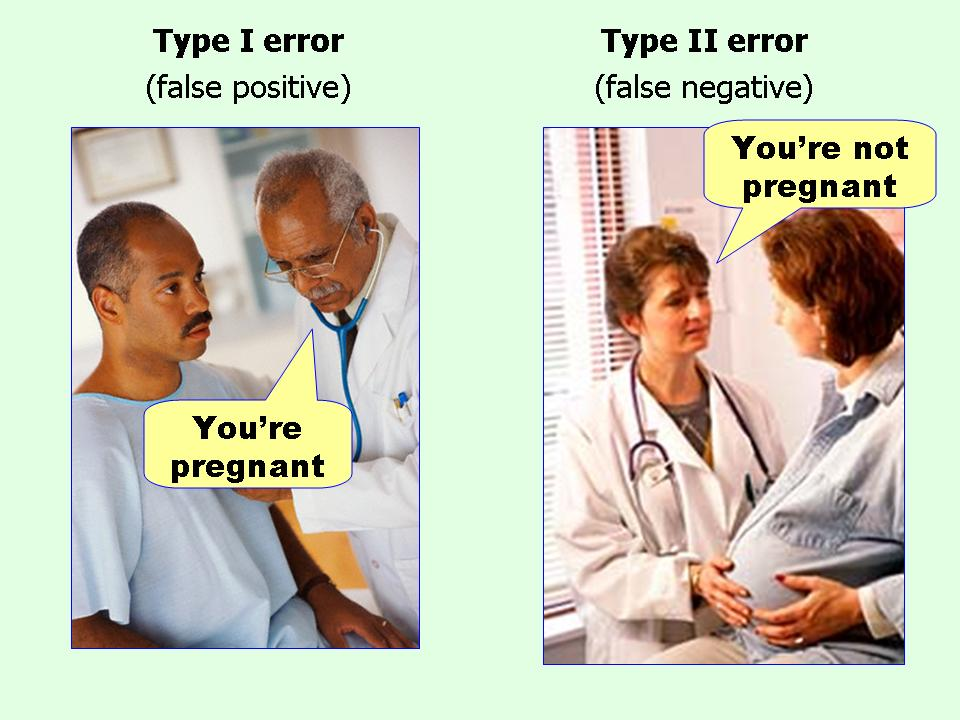

Полезно понимать, что такое уровень значимости и мощность, глядя на распределения.

Важно: речь идёт не о распределении самой метрики, а о распределении **статистики**, например разности средних между группами. По ЦПТ она примерно нормальна, а её разброс задаётся стандартной ошибкой. При верной $H_0$ она распределена вокруг нуля, а при верной $H_1$ вокруг эффекта $\delta$, если в тестовой группе метрика выросла на $+\delta$.

Рассмотрим односторонний тест: отвергаем $H_0$, если статистика превысила критическое значение.

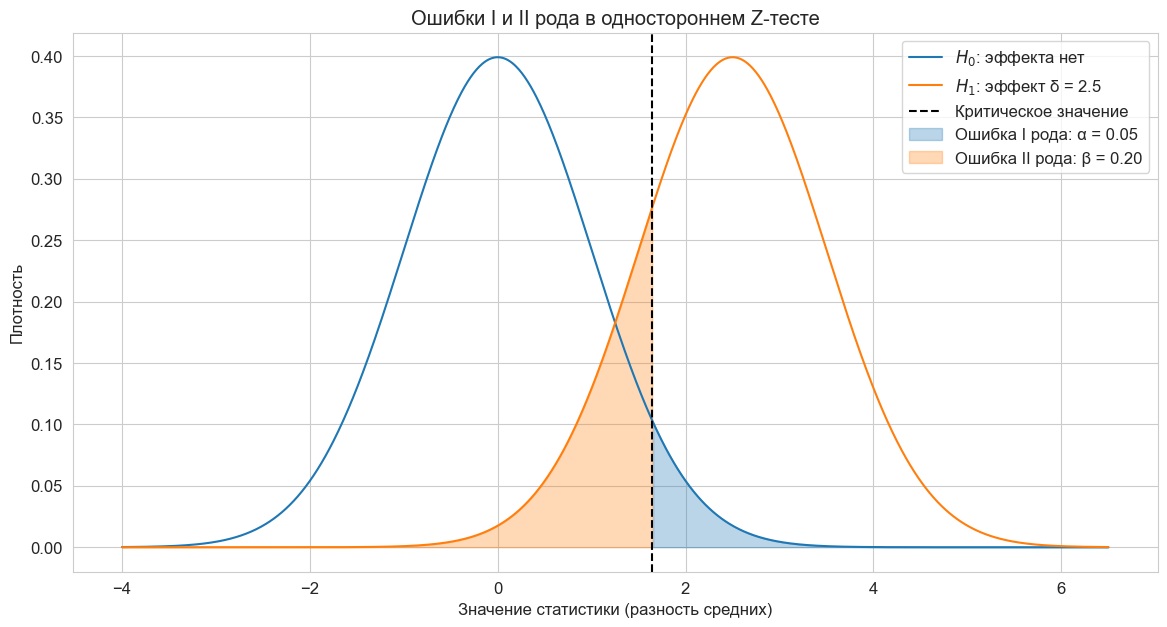

In [5]:
plot_error_distributions(delta=2.5, se=1.0, alpha=0.05)

Получается, что

* **Ошибка 1 рода ($\alpha$)** — площадь под кривой распределения статистики при верной $H_0$ правее критического значения: это квантиль уровня $1-\alpha$ распределения $H_0$;
* **Ошибка 2 рода ($\beta$)** — площадь под кривой распределения статистики при верной $H_1$ левее того же критического значения.

**Как связаны α, β, эффект и размер выборки**

С ростом выборки стандартная ошибка падает, распределения сужаются и расходятся. При том же эффекте и том же $\alpha$ ошибка второго рода уменьшается, а мощность растёт:

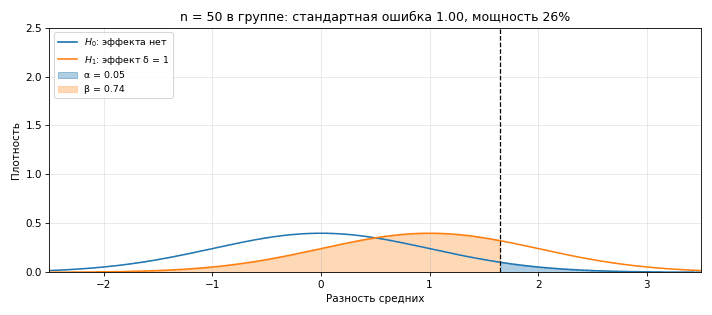

**Попробуйте сами.** Ячейка ниже интерактивная: запустите её в Colab или Jupyter и подвигайте ползунки. Проверьте, что происходит с $\beta$, если уменьшить $\alpha$ при том же $n$.

In [ ]:
def explore_power(delta: float = 1.0, sigma: float = 5.0, n: int = 500, alpha: float = 0.05) -> None:
    """Показывает ошибки I и II рода для двух групп по n наблюдений."""
    se = sigma * np.sqrt(2 / n)
    plot_error_distributions(delta=delta, se=se, alpha=alpha)
    power = stats.norm.sf(stats.norm.ppf(1 - alpha) - delta / se)
    mde = (stats.norm.ppf(1 - alpha) + stats.norm.ppf(0.8)) * se
    print(f'Стандартная ошибка: {se:.3f} | мощность: {power:.1%} | MDE при мощности 80%: {mde:.3f}')


interact(explore_power,
         delta=FloatSlider(value=1.0, min=0.0, max=3.0, step=0.1, description='δ'),
         sigma=FloatSlider(value=5.0, min=1.0, max=15.0, step=0.5, description='σ'),
         n=IntSlider(value=500, min=50, max=5000, step=50, description='n в группе'),
         alpha=FloatSlider(value=0.05, min=0.001, max=0.2, step=0.005, readout_format='.3f', description='α'));

### MDE & sample size calculation

На графике выше видно, что чем больше эффект $\delta$, тем дальше распределения друг от друга и тем меньше ошибка 2 рода. Интуитивно это понятно: чем явнее разница, тем легче её обнаружить.

Значит, если заранее задать ошибку 2 рода, то найдётся такой эффект, меньше которого тест с нужной вероятностью обнаружить не сможет. Это **MDE (Minimum Detectable Effect)** — наименьший эффект $\delta$, при котором при заданном уровне значимости $\alpha$ мощность теста не ниже $1-\beta$.

Важно: MDE не значит, что эффекты меньше него нельзя обнаружить совсем. Тест может их найти, но с вероятностью ниже $1-\beta$.

Как уменьшить MDE при фиксированных $\alpha$ и $\beta$? Нужно «ужать» распределения статистики, то есть уменьшить её стандартную ошибку. Для разности средних в двух группах по $n$ наблюдений она равна $\sigma\sqrt{2/n}$, поэтому
$$
\text{MDE} = \left(z_{1-\alpha} + z_{1-\beta}\right)\sigma\sqrt{\frac{2}{n}}.
$$

Отсюда важная зависимость: чем больше выборка, тем меньше MDE, но не пропорционально: **MDE убывает как $1/\sqrt{n}$**. Чтобы уменьшить MDE вдвое, выборку нужно увеличить вчетверо. Второй рычаг — уменьшить дисперсию $\sigma^2$ самой метрики (занятие 1.04).

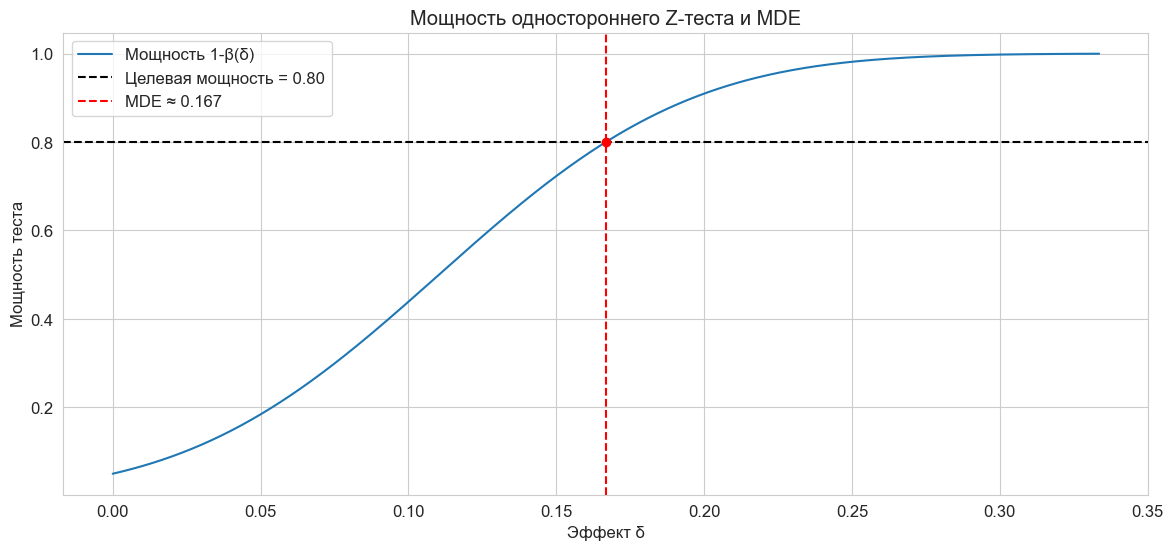

При n=1000 в группе, σ=1.50, α=0.05 и мощности 0.80 MDE ≈ 0.167


0.16679780437430508

In [7]:
calculate_and_plot_mde(n = 1000,
                       sigma = 1.5,
                       alpha = 0.05,
                       target_power = 0.8)

Для дизайна теста MDE и размер выборок являются такими же важными параметрами, как и ошибки 1 и 2 рода. Тем не менее из-за их зависимости можно всегда найти одно через другое, а значит есть 2 пути определения:

* Определяем **доступный размер выборки**, а потом считаем по формулам **MDE**;

  Бывает ситуация, когда решение должно происходить от размера доступной выборки.

  1. Предположим, что бизнес-заказчику важна репутация своего продукта, поэтому он готов экспериментировать не более чем на X% выборки. Тогда логичным решением будет посчитать MDE и констатировать ему, что на выделенной группе пользователей не сможем надёжно увидеть эффект менее **MDE**. Далее по-хорошему соотнести рассчитанный **MDE** с ожиданиями от внедрения изменения, и если ожидаемый эффект меньше, то необходимо либо настаивать на увеличении выборки до тех пор, пока не получим достаточно малый **MDE** (по сути второй подход), либо вообще не проводить тест: он будет заведомо бессмысленным.

  2. Продукт довольно молодой и готов экспериментировать сразу на всех своих пользователях, в таком случае (раз не можем увеличить размер выборки) нужно просто посчитать MDE и держать в голове, что если нет изменения, то либо оно при текущем наборе пользователей крайне мало, либо же эффекта нет.

* Определяем **MDE**, а потом считаем по формулам **размер выборок**

  Этот путь исходит от того, что мы понимаем либо приблизительный эффект, который изменение может за собой нести (например из профессионального опыта), либо же минимально экономически выгодный эффект, меньше которого мы не готовы принимать. Отсюда мы можем принять **MDE** за эти значения и уже высчитывать достаточный размер выборки.

К сожалению, не для всех случаев есть готовые формулы, которые позволят легко посчитать **необходимый размер выборки (sample size)** или **MDE**. Отсюда рассмотрим два исхода:

**1. "Приятные" метрики**

  Метрика считается "приятной", если удовлетворяет условиям:

  * Асимптотическая нормальность: Распределение сходится к нормальному при n → ∞
  * Независимость наблюдений: Данные i.i.d. (independent and identically distributed)
  * Известная дисперсия: можно оценить σ² по историческим данным
  * Достаточный объём данных: правило «n > 30» подходит только для распределений без тяжёлых хвостов (см. практику 1.П1)

  К таким метрикам относятся:

  * Средние значения (средний чек, время на сайте)
  * Пропорции (конверсии, доля платящих пользователей)

  Для таких метрик есть готовая формула

$$
N = \left(\frac{\sigma_A^2}{w_A} + \frac{\sigma_B^2}{w_B}\right)\frac{\left( z_{1-\alpha} + z_{1-\beta} \right)^2}{\text{MDE}^2}
\quad \text{где } N \text{ — общий размер выборки, } w_i = n_i/N \text{ — доля пользователей в группе } i
$$

Для двух равных групп с одинаковой дисперсией это даёт $N = \dfrac{4\sigma^2 (z_{1-\alpha} + z_{1-\beta})^2}{\text{MDE}^2}$, то есть $n = \dfrac{2\sigma^2 (z_{1-\alpha} + z_{1-\beta})^2}{\text{MDE}^2}$ в каждой группе. Для конверсий вместо $\sigma^2$ подставляют $p(1-p)$.

Здесь $z_{1-\alpha}$ для одностороннего теста, для двустороннего $z_{1-\alpha/2}$.

**2. "Неприятные" метрики**

"Неприятные" метрики - это те, которые не входят в первый случай. К ним относятся

* Медианы и квантили
* Метрики с тяжёлыми хвостами (LTV, ARPU)
* Ratio-метрики
* Пользовательские сложные метрики

В таком случае мы можем:
1. Попытаться привести метрики к приятным (например логарифмировать метрики с тяжёлыми хвостами) и посчитать по формуле
2. Использовать исторические данные, чтобы эмпирически высчитать необходимые параметры (подробнее [тут](https://habr.com/ru/companies/lamoda/articles/707816/)):
    
    2.1. Если распределение не слишком далеко от нормального, можно оценить выборочную дисперсию на истории и использовать формулу для «приятных» метрик.

    2.2. Если распределение сильно отличается от нормального, мощность оценивают симуляцией:

    1. Задать сетку кандидатов $n$.
    2. Для каждого $n$ и для каждой итерации $j=1 \dots J$:
        1. Сэмплировать с возвращением из исторических данных **две независимые** выборки размера $n$: $C_j$ и $T_j$. Брать одну и ту же выборку и сдвигать её нельзя: разность средних станет постоянной, и оценка мощности потеряет смысл.
        2. Добавить эффект к тестовой группе: $T_j = \{t_{j,1}+\delta,\dots,t_{j,n}+\delta\}$.
        3. Применить выбранный критерий.
        4. Зафиксировать, отвергли ли $H_0$ (p-value < $\alpha$).
    3. По итогам $J$ повторов оценить долю «отвергли»: это и есть эмпирическая мощность при данном $n$.
    4. Найти минимальное $n$, при котором мощность не ниже требуемой.

**Калькулятор для конверсии.** Формула выше для доли $p$ в обеих группах: подберите параметры ползунками. Ячейка ниже считает общий размер выборки и наглядно показывает цену маленького эффекта и неравного сплита.

In [ ]:
def conversion_sample_size(base_rate: float, mde_relative: float, test_share: float = 0.5,
                           alpha: float = 0.05, power: float = 0.8) -> int:
    """Общий размер выборки для двустороннего теста конверсии, MDE задан как относительный прирост."""
    test_rate = base_rate * (1 + mde_relative)
    z_sum = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
    variance = base_rate * (1 - base_rate) / (1 - test_share) + test_rate * (1 - test_rate) / test_share
    return int(np.ceil(variance * z_sum ** 2 / (test_rate - base_rate) ** 2))


def sample_size_calculator(base_rate: float = 0.10, mde_relative: float = 0.05, test_share: float = 0.5,
                           alpha: float = 0.05, power: float = 0.8, daily_users: int = 10_000) -> None:
    """Печатает размер выборки и длительность теста, рисует зависимость N от MDE и сплита."""
    total = conversion_sample_size(base_rate, mde_relative, test_share, alpha, power)
    print(f'Нужно {total:,} пользователей: {total * (1 - test_share):,.0f} в контроле и {total * test_share:,.0f} в тесте.')
    print(f'При {daily_users:,} пользователей в день это {np.ceil(total / daily_users):.0f} дн.')

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    mdes = np.linspace(0.01, 0.20, 100)
    axes[0].plot(mdes * 100, [conversion_sample_size(base_rate, m, test_share, alpha, power) for m in mdes])
    axes[0].scatter([mde_relative * 100], [total], color='#e74c3c', zorder=3)
    axes[0].set_yscale('log')
    axes[0].set_title('Чем меньше эффект, тем больше выборка')
    axes[0].set_xlabel('Относительный MDE, %')
    axes[0].set_ylabel('Общий размер выборки')

    shares = np.linspace(0.05, 0.95, 91)
    axes[1].plot(shares * 100, [conversion_sample_size(base_rate, mde_relative, s, alpha, power) for s in shares])
    axes[1].scatter([test_share * 100], [total], color='#e74c3c', zorder=3)
    axes[1].set_title('Чем неравнее сплит, тем больше выборка')
    axes[1].set_xlabel('Доля теста, %')
    axes[1].set_ylabel('Общий размер выборки')
    plt.tight_layout()
    plt.show()


interact(sample_size_calculator,
         base_rate=FloatSlider(value=0.10, min=0.005, max=0.5, step=0.005, readout_format='.3f', description='Конверсия'),
         mde_relative=FloatSlider(value=0.05, min=0.01, max=0.3, step=0.01, description='MDE, отн.'),
         test_share=FloatSlider(value=0.5, min=0.05, max=0.95, step=0.05, description='Доля теста'),
         alpha=FloatSlider(value=0.05, min=0.001, max=0.1, step=0.001, readout_format='.3f', description='α'),
         power=FloatSlider(value=0.8, min=0.5, max=0.99, step=0.01, description='Мощность'),
         daily_users=IntSlider(value=10_000, min=1_000, max=200_000, step=1_000, description='В день'));

Нужно 115,520 пользователей: 57,760 в контроле и 57,760 в тесте.
При 10,000 пользователей в день это 12 дн.


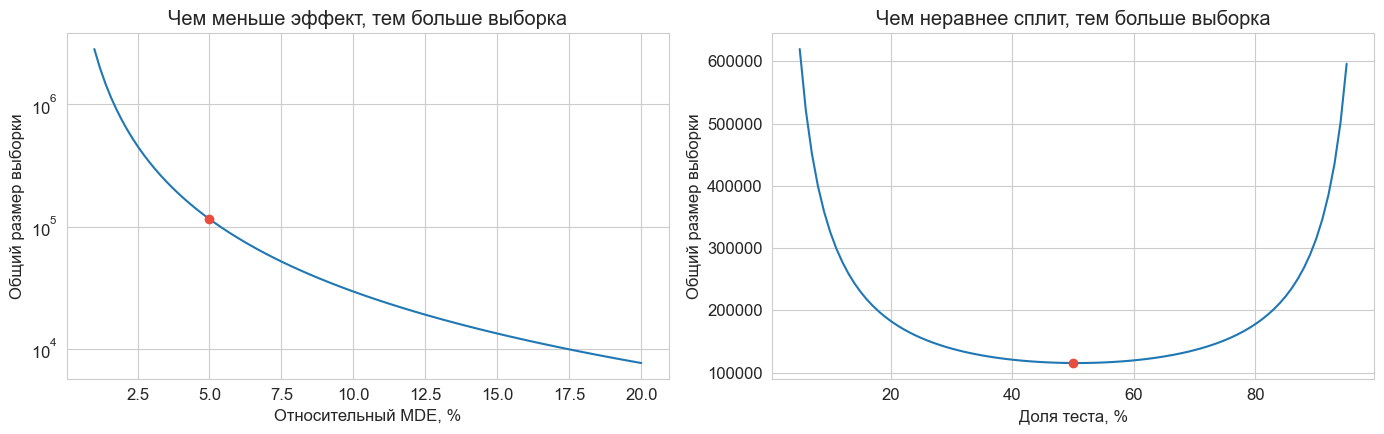

In [9]:
sample_size_calculator(base_rate=0.10, mde_relative=0.05)

### Статистические критерии

Теперь переходим непосредственно к статистическим критериям - лакмусовым бумажкам, которые говорят, а является ли **статистически значимой** разница в метриках между тестовой и контрольной группой.

[Статистически значимая разница](https://en.wikipedia.org/wiki/Statistical_significance) — разница, которую трудно объяснить случайностью. Это не гарантия, что эффект есть: при верной $H_0$ значимый результат всё равно появится с вероятностью $\alpha$. Мерой служит p-value — вероятность получить такую или более экстремальную разницу при верной $H_0$. Это **не** вероятность того, что $H_0$ верна.

Есть несколько категорий критериев:
  * Параметрические - критерии, которые применяются к данным с определёнными распределениями
  * Непараметрические - критерии, которые не делают предположений о форме распределения данных

Вообще критериев существует огромное множество ([обзор 1](https://www.statskingdom.com/index.html) и [обзор 2](https://www.biostathandbook.com/testchoice.html)), но в онлайн A/B зачастую применяются следующие:

#### Параметрические тесты

##### $z$-тест

$z$-тест — это параметрический статистический тест, который используется для проверки гипотез о средних значениях одной или двух генеральных совокупностей. Z-тест традиционно применяется, когда известна дисперсия генеральной совокупности или когда размер выборки достаточно велик (как правило, более 30 наблюдений), чтобы выборочное стандартное отклонение могло служить надежной оценкой генерального. В последнем случае, благодаря Центральной Предельной Теореме (ЦПТ), распределение выборочных средних аппроксимируется нормальным распределением, что позволяет использовать Z-статистику.

**$z$-тест используется для проверки следующих типов гипотез:**
*   Сравнение среднего одной выборки с известным значением генеральной совокупности.
*   Сравнение средних двух независимых выборок.
*   Сравнение доли в одной выборке с известной долей генеральной совокупности.
*   Сравнение долей двух независимых выборок.

**Предпосылки $z$-теста**

Для корректного применения $z$-теста необходимо выполнение нескольких предпосылок:
1.  **Нормальность распределения выборочных средних**:
    *   Если исходные данные генеральной совокупности распределены нормально, то выборочные средние также будут распределены нормально.
    *   Если исходные данные не распределены нормально, но размер выборки достаточно велик, то согласно **[Центральной Предельной Теореме (ЦПТ)](https://ru.wikipedia.org/wiki/Центральная_предельная_теорема)**, распределение выборочных средних будет аппроксимироваться нормальным распределением. Это означает, что $z$-тест может быть использован даже для данных из ненормального распределения, например, экспоненциального.
2.  **Независимость наблюдений**: Все наблюдения в выборках должны быть независимыми друг от друга. Если данные зависимы (например, повторные измерения на одних и тех же объектах), то $z$-тест может работать некорректно, приводя к завышенной ошибке первого рода.
3.  **Известная дисперсия генеральной совокупности или большой размер выборки**: Традиционно $z$-тест требует знания стандартного отклонения генеральной совокупности $\sigma$. Однако на практике $\sigma$ часто неизвестна. В таких случаях, если размер выборки достаточно велик, выборочное стандартное отклонение $s$ может использоваться в качестве хорошей оценки $\sigma$.

**Формулировка Z-критерия**

Рассмотрим наиболее распространенный случай $z$-теста — **сравнение средних двух независимых выборок**.

* **Нулевая гипотеза ($H_0$):** Разность средних значений двух генеральных совокупностей равна некоторому гипотетическому значению $D_0$

    Чаще всего $D_0=0$, что означает отсутствие эффекта. $H_0: \mu_1 = \mu_2$ (или $\mu_1 - \mu_2 = 0$)

* **Альтернативная гипотеза ($H_1$):** Средние значения отличаются.

    * $H_1: \mu_1 \neq \mu_2$ (двухсторонний тест)
    * $H_1: \mu_1 > \mu_2$ (односторонний тест, правый хвост)
    * $H_1: \mu_1 < \mu_2$ (односторонний тест, левый хвост)

**$z$-статистика для сравнения средних двух независимых выборок:**

$$
Z = \frac{(\bar{X}_1 - \bar{X}_2) - (\mu_1 - \mu_2)}{\sqrt{\frac{\sigma_1^2}{n_1} + \frac{\sigma_2^2}{n_2}}}
$$

где:
*   $\bar{X}_1$ и $\bar{X}_2$ — выборочные средние первой и второй групп соответственно.
*   $n_1$ и $n_2$ — размеры выборок первой и второй групп соответственно.
*   $\mu_1 - \mu_2$ — гипотетическая разность средних (часто $0$ под $H_0$).
*   $\sigma_1^2$ и $\sigma_2^2$ — дисперсии генеральных совокупностей первой и второй групп. Если они неизвестны, для больших выборок используются выборочные дисперсии $s_1^2$ и $s_2^2$ в качестве оценок.

**Критерий принятия решения**

Решение, отвергать ли нулевую гипотезу, основывается на сравнении $z$-статистики с критическими значениями из стандартного нормального распределения или на сравнении **p-value** с уровнем значимости $\alpha$.

1.  **Метод p-value**:
    *   **p-value** — это вероятность получить наблюдаемые или более экстремальные результаты, если нулевая гипотеза верна.
    *   Если **p-value < $\alpha$**, нулевая гипотеза отвергается. Это означает, что наблюдаемые различия статистически значимы, и мы заключаем, что эффект существует.
    *   Если **p-value $\ge \alpha$**, нулевая гипотеза не отвергается. Это означает, что наблюдаемые различия не являются статистически значимыми, и мы не можем утверждать наличие эффекта.

2.  **Метод доверительного интервала (ДИ)**:
    * Доверительный интервал уровня $1-\alpha$ строится так, что при многократном повторении эксперимента он накрывает истинное значение параметра в доле $1-\alpha$ случаев. Это свойство процедуры: для одного конкретного интервала истинное значение либо внутри него, либо нет.
    * Если значение 0 (или гипотетическая разность) **не** попадает в доверительный интервал, нулевая гипотеза отвергается.
    * Для разности средних ДИ строится следующим образом:
    
$$\left(\bar{X}_1 - \bar{X}_2 \right) \pm Z_{1-\alpha/2} \cdot \sqrt{\frac{\sigma_1^2}{n_1} + \frac{\sigma_2^2}{n_2}}$$

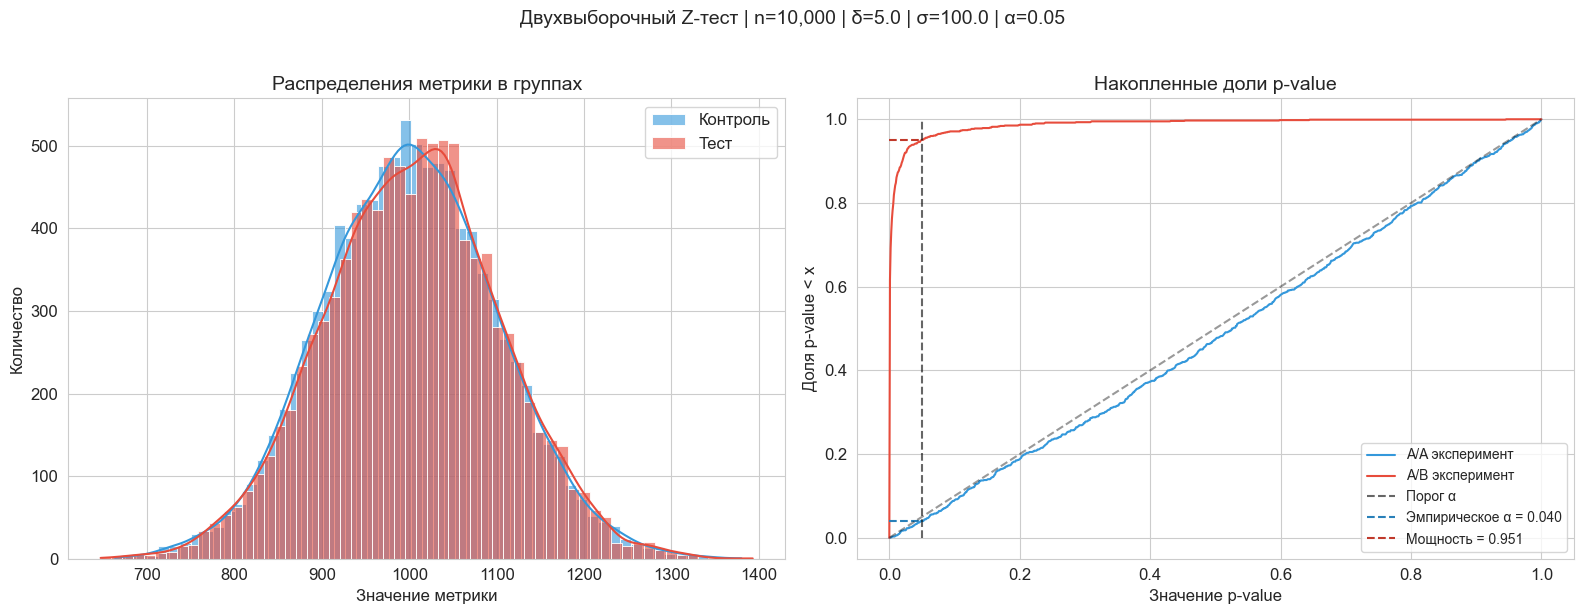

In [10]:
class ZTestResult(TypedDict):
    difference: float
    z_score: float
    p_value: float
    std_error: float


@dataclass(frozen=True)
class ZTestScenario:
    """Параметры моделирования для двухвыборочного Z-теста."""

    mu_ctrl: float
    mu_test: float
    sigma: float
    sample_size: int
    simulations: int
    alpha: float
    pop_std: Optional[float] = None
    seed: Optional[int] = None


def two_sample_z_test(control: FloatArray,
                      test: FloatArray,
                      pop_std: Optional[float] = None) -> ZTestResult:
    """
    Вычисляет статистику Z-теста для независимых выборок.
    """
    n_ctrl, n_test = len(control), len(test)
    mean_ctrl, mean_test = float(np.mean(control)), float(np.mean(test))
    diff = mean_test - mean_ctrl

    if pop_std is not None:
        std_ctrl = std_test = pop_std
    else:
        std_ctrl = float(np.std(control, ddof=1))
        std_test = float(np.std(test, ddof=1))

    std_error = np.sqrt(std_ctrl ** 2 / n_ctrl + std_test ** 2 / n_test)
    z_score = diff / std_error
    p_value = 2 * (1 - stats.norm.cdf(abs(z_score)))

    return ZTestResult(
        difference=diff,
        z_score=z_score,
        p_value=p_value,
        std_error=std_error,
    )


def generate_data(mu_ctrl: float,
                  mu_test: float,
                  sigma: float,
                  sample_size: int,
                  seed: Optional[int] = None) -> tuple[FloatArray, FloatArray]:
    """Генерирует контрольную и тестовую выборки с указанными параметрами."""
    rng = np.random.default_rng(seed)
    control = rng.normal(loc=mu_ctrl, scale=sigma, size=sample_size)
    test = rng.normal(loc=mu_test, scale=sigma, size=sample_size)
    return control, test


def run_simulation(n_sim: int,
                   sample_size: int,
                   mu_ctrl: float,
                   mu_test: float,
                   sigma: float,
                   pop_std: Optional[float] = None,
                   seed: Optional[int] = None) -> FloatArray:
    """Оценивает распределение p-value с помощью Монте-Карло."""
    rng = np.random.default_rng(seed)
    p_values = np.empty(n_sim, dtype=float)

    for i in range(n_sim):
        control = rng.normal(mu_ctrl, sigma, sample_size)
        test = rng.normal(mu_test, sigma, sample_size)
        result = two_sample_z_test(control, test, pop_std=pop_std)
        p_values[i] = result['p_value']

    return p_values


def plot_combined_distributions(control: FloatArray,
                                test: FloatArray,
                                pvalues_aa: FloatArray,
                                pvalues_ab: FloatArray,
                                alpha: float = 0.05,
                                subtitle: str = '') -> None:
    """Отрисовывает распределения метрики и соответствующих p-value."""
    fig, (ax_metrics, ax_pvalues) = plt.subplots(1, 2, figsize=(16, 6))

    sns.histplot(control, color='#3498db', alpha=0.6, kde=True, label='Контроль', ax=ax_metrics)
    sns.histplot(test, color='#e74c3c', alpha=0.6, kde=True, label='Тест', ax=ax_metrics)
    ax_metrics.set_title('Распределения метрики в группах', fontsize=14)
    ax_metrics.set_xlabel('Значение метрики')
    ax_metrics.set_ylabel('Количество')
    ax_metrics.legend()

    plot_pvalue_cdf(ax_pvalues, pvalues_aa, pvalues_ab, alpha, 'Накопленные доли p-value')

    plt.suptitle(subtitle, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()


scenario = ZTestScenario(
    mu_ctrl=1_000,
    mu_test=1_005,
    sigma=100.0,
    sample_size=10_000,
    simulations=1_000,
    alpha=0.05,
    pop_std=100.0,
    seed=66,
)

control_sample, test_sample = generate_data(
    mu_ctrl=scenario.mu_ctrl,
    mu_test=scenario.mu_test,
    sigma=scenario.sigma,
    sample_size=scenario.sample_size,
    seed=scenario.seed,
)

pvalues_aa = run_simulation(
    n_sim=scenario.simulations,
    sample_size=scenario.sample_size,
    mu_ctrl=scenario.mu_ctrl,
    mu_test=scenario.mu_ctrl,
    sigma=scenario.sigma,
    pop_std=scenario.pop_std,
    seed=scenario.seed,
)

pvalues_ab = run_simulation(
    n_sim=scenario.simulations,
    sample_size=scenario.sample_size,
    mu_ctrl=scenario.mu_ctrl,
    mu_test=scenario.mu_test,
    sigma=scenario.sigma,
    pop_std=scenario.pop_std,
    seed=(scenario.seed + 1) if scenario.seed is not None else None,
)

subtitle_text = (
    f'Двухвыборочный Z-тест | n={scenario.sample_size:,} | '
    f'δ={scenario.mu_test - scenario.mu_ctrl:.1f} | σ={scenario.sigma:.1f} | α={scenario.alpha:.2f}'
)

plot_combined_distributions(
    control=control_sample,
    test=test_sample,
    pvalues_aa=pvalues_aa,
    pvalues_ab=pvalues_ab,
    alpha=scenario.alpha,
    subtitle=subtitle_text,
)

##### $t$-тест

$t$-тест — параметрический статистический тест, используемый для проверки гипотез о средних значениях генеральных совокупностей, когда дисперсия генеральной совокупности неизвестна. Он основан на $t$-распределении Стьюдента, которое учитывает неопределённость, вызванную оценкой дисперсии по выборке. $t$-тест особенно важен для малых выборок (n<30), но применим и для больших выборок.

**$t$-тест используется для проверки следующих гипотез**

* Сравнение выборочного среднего с гипотетическим значением генеральной совокупности $\mu_0$.
* Сравнение средних двух несвязанных групп.
* Сравнение средних измерений, полученных от одних и тех же объектов (зависимые выборки).

**Предпосылки $t$-теста**

Для корректного применения $t$-теста необходимо выполнение нескольких предпосылок:
1.  **Нормальность распределения выборочных средних**:
    *   Если исходные данные генеральной совокупности распределены нормально, то выборочные средние также будут распределены нормально.
    *   Если исходные данные не распределены нормально, но размер выборки достаточно велик (n>30), то согласно **[Центральной Предельной Теореме (ЦПТ)](https://ru.wikipedia.org/wiki/Центральная_предельная_теорема)**, распределение выборочных средних будет аппроксимироваться нормальным распределением. На маленьких выборках $t$-распределение с более тяжёлыми хвостами учитывает, что дисперсия оценена по данным, но точным оно остаётся только для нормальных данных. Поэтому при малых $n$ и сильно скошенных данных $t$-тест может держать ошибку первого рода неточно.
2.  **Независимость наблюдений**:
    *   **Классический двухвыборочный $t$-тест (Student's $t$-test)** предполагает, что сравниваемые выборки независимы. Это означает, что наблюдения в одной группе не должны влиять на наблюдения в другой группе. В A/B-тестировании это обычно достигается случайным разделением пользователей из генеральной совокупности на контрольную и тестовую группы.
    *   Однако на практике встречаются **зависимые выборки**. Например, когда одна и та же группа людей измеряется до и после воздействия. В таких случаях применение стандартного двухвыборочного $t$-теста для независимых выборок может привести к некорректным результатам, так как предположение о независимости нарушается. Для зависимых выборок используется **одновыборочный $t$-тест для попарных разностей** (Paired $t$-test), который рассматривает разницу между измерениями одной и той же единицы наблюдения.
3.  **Гомогенность дисперсий**     

    *   Классический $t$-тест предполагает, что дисперсии генеральных совокупностей, из которых взяты выборки, равны.
    *   Если дисперсии генеральных совокупностей различаются, особенно при несбалансированных размерах выборок (**сплит не 50 на 50**) или **малых выборках**, применение классического $t$-теста может привести к увеличению ошибки первого рода (ложноположительных срабатываний). В таких ситуациях рекомендуется использовать **$t$-тест Уэлча (Welch's $t$-test)**, который не предполагает равенства дисперсий. Важно отметить, что для **больших выборок** и сбалансированного сплита (50 на 50) классический $t$-тест часто ведет себя корректно даже при разных дисперсиях.

**Формулировка $t$-критерия**

*   **Одновыборочный $t$-тест (сравнение среднего выборки с заданной константой)**

    $$t = \frac{\bar{X} - \mu_0}{s / \sqrt{n}}$$
    *   $\bar{X}$ — выборочное среднее.
    *   $\mu_0$ — заданное значение для сравнения.
    *   $s$ — выборочное стандартное отклонение.
    *   $n$ — размер выборки.

    Для этой статистики степени свободы $df = n-1$

*   **Двухвыборочный $t$-тест для независимых выборок (классический критерий Стьюдента при равных дисперсиях)**

    $$t = \frac{\bar{X}_1 - \bar{X}_2}{s_p \sqrt{1/n_1 + 1/n_2}}$$
    *   $\bar{X}_1$, $\bar{X}_2$ — выборочные средние двух групп.
    *   $s_p$ — объединенное стандартное отклонение.
    *   $n_1$, $n_2$ — размеры выборок.
    *   $s_p = \sqrt\frac{(n_1-1)s_1^2 + (n_2-1)s_2^2}{n_1 + n_2 - 2}$
    *   Для большого размера выборки (когда $n_1=n_2=n$) и если обе выборки из одной генеральной совокупности с $\sigma$, то знаменатель упрощается до $\sqrt{2 \sigma^2 / n}$.

    Для этой статистики степени свободы $df = n_1 + n_2 - 2$

*   **Двухвыборочный $t$-тест Уэлча (без предположения о равенстве дисперсий)**

    $$t = \frac{\bar{X}_1 - \bar{X}_2}{\sqrt{s_1^2/n_1 + s_2^2/n_2}}$$

    Степени свободы считаются по приближённой формуле Саттертуэйта:

    $$df \approx \frac{\left(s_1^2/n_1 + s_2^2/n_2\right)^2}{\frac{(s_1^2/n_1)^2}{n_1-1} + \frac{(s_2^2/n_2)^2}{n_2-1}}$$

    Тест не теряет в качестве при равных дисперсиях, поэтому в A/B-тестах его можно использовать по умолчанию.

*   **Одновыборочный $t$-тест для попарных разностей (Paired $t$-test) для зависимых выборок**

    Эта задача переформулируется. Вместо сравнения средних двух выборок, создается новая выборка попарных разностей $D_i = X_{1i} - X_{2i}$. Затем применяется одновыборочный $t$-тест к этой выборке разностей, проверяя гипотезу о том, что среднее разностей равно нулю:
    $$t = \frac{\bar{D}}{s_D / \sqrt{n}}$$
    *   $\bar{D}$ — среднее попарных разностей.
    *   $s_D$ — стандартное отклонение попарных разностей.
    *   $n$ — количество пар наблюдений.

    Для этой статистики степени свободы $df = n-1$
    
    При случайном подборе отклонение разностей будет $\sigma_D = \sqrt{2}\sigma_{\text{gen}}$. Однако при неслучайном, например, парном подборе похожих объектов, $\sigma_D$ может быть существенно меньше $\sqrt{2}\sigma_{\text{gen}}$.

**Критерии принятия решений:**

Решение, отвергать ли нулевую гипотезу, основывается на сравнении $t$-статистики с критическими значениями из распределения Стьюдента или на сравнении **p-value** с уровнем значимости $\alpha$.

1.  **Метод p-value**:
    *   **p-value** — это вероятность получить наблюдаемые или более экстремальные результаты, если нулевая гипотеза верна.
    *   Если **p-value < $\alpha$**, нулевая гипотеза отвергается. Это означает, что наблюдаемые различия статистически значимы, и мы заключаем, что эффект существует.
    *   Если **p-value $\ge \alpha$**, нулевая гипотеза не отвергается. Это означает, что наблюдаемые различия не являются статистически значимыми, и мы не можем утверждать наличие эффекта.

2.  **Метод доверительного интервала (ДИ)**:
    * Доверительный интервал уровня $1-\alpha$ строится так, что при многократном повторении эксперимента он накрывает истинное значение параметра в доле $1-\alpha$ случаев. Это свойство процедуры: для одного конкретного интервала истинное значение либо внутри него, либо нет.
    * Если значение 0 (или гипотетическая разность) **не** попадает в доверительный интервал, нулевая гипотеза отвергается. Если 0 попадает в интервал, нулевая гипотеза не отвергается.
    * Для разности средних в варианте Уэлча ДИ строится следующим образом (степени свободы $df$ по формуле Саттертуэйта):
    
$$\left(\bar{X}_1 - \bar{X}_2 \right) \pm t_{(1-\alpha/2,\,df)} \cdot \sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}
$$

Сценарий для независимого t-теста


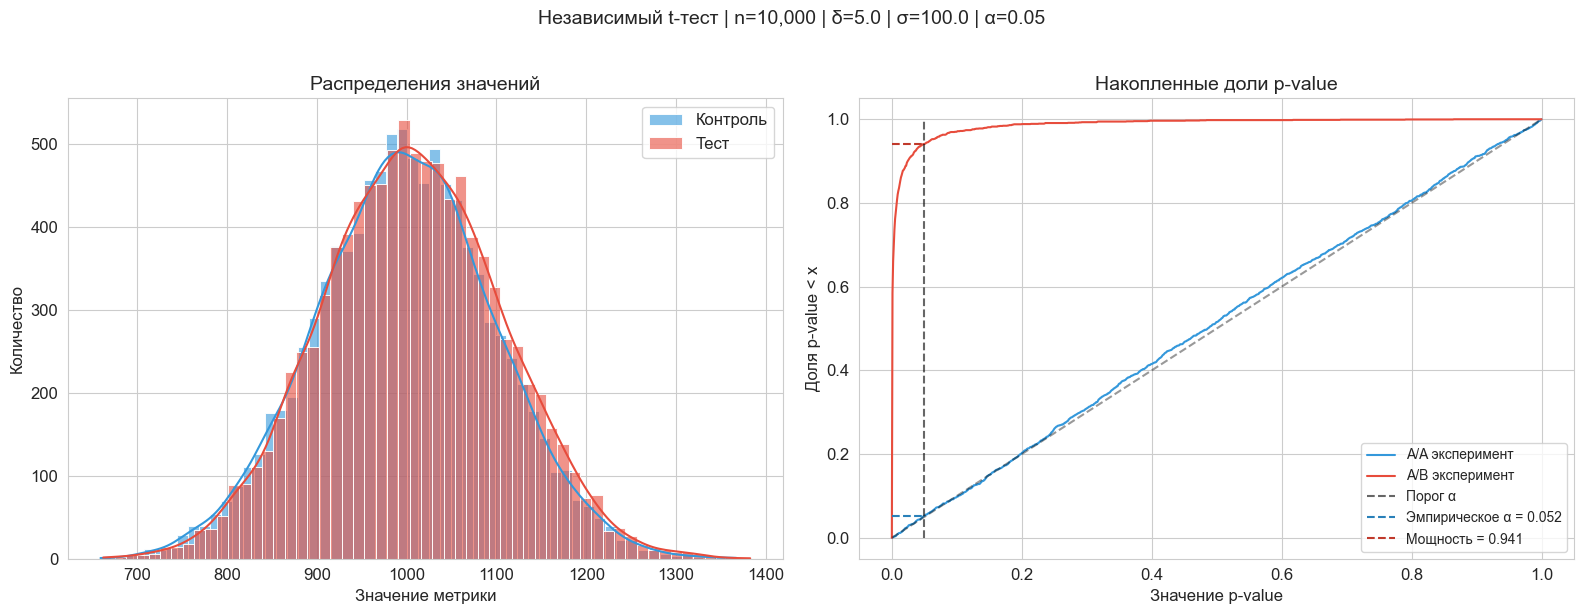


Сценарий для парного t-теста


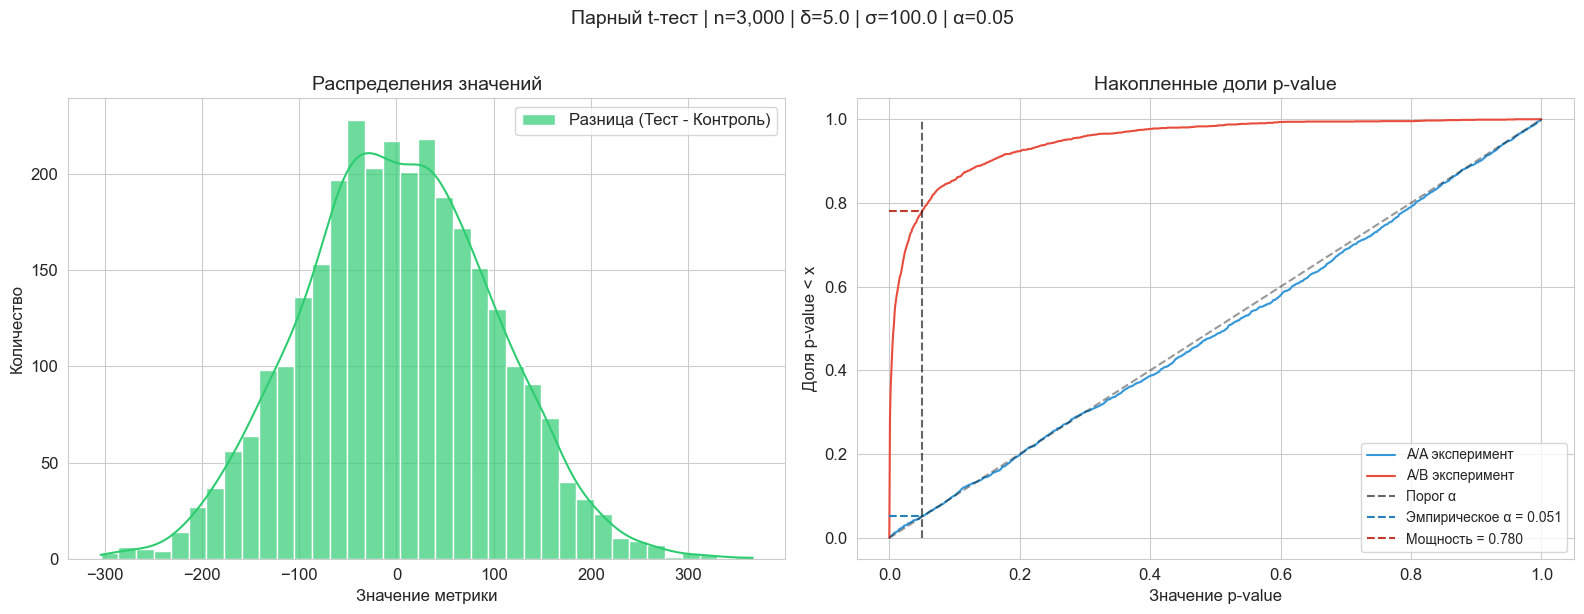

In [11]:
class TTestResult(TypedDict):
    difference: float
    t_statistic: float
    p_value: float
    mean_control: float
    mean_test: float


@dataclass(frozen=True)
class TTestScenario:
    """Параметры моделирования для t-теста."""

    mu_ctrl: float
    mu_test: float
    sigma: float
    sample_size: int
    simulations: int
    alpha: float
    paired: bool = False
    seed: Optional[int] = None


def generate_data(mu_ctrl: float,
                  mu_test: float,
                  sigma: float,
                  sample_size: int,
                  paired: bool = False,
                  correlation: float = 0.5,
                  seed: Optional[int] = None) -> tuple[FloatArray, FloatArray]:
    """
    Формирует данные для независимых или попарных наблюдений.
    """
    rng = np.random.default_rng(seed)
    if not paired:
        control = rng.normal(mu_ctrl, sigma, sample_size)
        test = rng.normal(mu_test, sigma, sample_size)
        return control, test

    # Дисперсия каждого наблюдения равна sigma², а корреляция между парами равна correlation
    shared_noise = rng.normal(0, sigma * np.sqrt(correlation), sample_size)
    residual_scale = sigma * np.sqrt(1 - correlation)
    control = mu_ctrl + shared_noise + rng.normal(0, residual_scale, sample_size)
    test = mu_test + shared_noise + rng.normal(0, residual_scale, sample_size)
    return control, test


def two_sample_t_test(control: FloatArray,
                      test: FloatArray,
                      paired: bool = False) -> TTestResult:
    """Вычисляет t-статистику (независимую или попарную)."""
    if paired:
        stat = stats.ttest_rel(control, test)
    else:
        stat = stats.ttest_ind(control, test, equal_var=False)  # тест Уэлча

    diff = float(np.mean(test) - np.mean(control))
    return TTestResult(
        difference=diff,
        t_statistic=float(stat.statistic),
        p_value=float(stat.pvalue),
        mean_control=float(np.mean(control)),
        mean_test=float(np.mean(test)),
    )


def run_simulation(n_sim: int,
                   sample_size: int,
                   mu_ctrl: float,
                   mu_test: float,
                   sigma: float,
                   paired: bool = False,
                   seed: Optional[int] = None) -> FloatArray:
    """Считает распределение p-value для заданного сценария."""
    rng = np.random.default_rng(seed)
    p_values = np.empty(n_sim)

    for i in tqdm(range(n_sim), desc='Симуляции t-теста', leave=False):
        if paired:
            ctrl, tst = generate_data(mu_ctrl, mu_test, sigma, sample_size, paired=True, seed=rng.integers(0, 1 << 32))
        else:
            ctrl = rng.normal(mu_ctrl, sigma, sample_size)
            tst = rng.normal(mu_test, sigma, sample_size)

        res = two_sample_t_test(ctrl, tst, paired=paired)
        p_values[i] = res['p_value']

    return p_values


def plot_combined_distributions(control: FloatArray,
                                test: FloatArray,
                                pvalues_aa: FloatArray,
                                pvalues_ab: FloatArray,
                                alpha: float,
                                subtitle: str,
                                paired: bool = False) -> None:
    """Отрисовывает распределения метрик и эмпирические CDF p-value."""
    fig, (ax_metrics, ax_pvalues) = plt.subplots(1, 2, figsize=(16, 6))

    if paired:
        diff = test - control
        sns.histplot(diff, color='#2ecc71', alpha=0.7, kde=True, label='Разница (Тест - Контроль)', ax=ax_metrics)
    else:
        sns.histplot(control, color='#3498db', alpha=0.6, kde=True, label='Контроль', ax=ax_metrics)
        sns.histplot(test, color='#e74c3c', alpha=0.6, kde=True, label='Тест', ax=ax_metrics)

    ax_metrics.set_title('Распределения значений', fontsize=14)
    ax_metrics.set_xlabel('Значение метрики')
    ax_metrics.set_ylabel('Количество')
    ax_metrics.legend()

    plot_pvalue_cdf(ax_pvalues, pvalues_aa, pvalues_ab, alpha, 'Накопленные доли p-value')

    plt.suptitle(subtitle, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()


def run_full_analysis(params: TTestScenario) -> None:
    """Полный сценарий: генерация, симуляции и визуализация."""
    control, test = generate_data(
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_test,
        sigma=params.sigma,
        sample_size=params.sample_size,
        paired=params.paired,
        seed=params.seed,
    )

    pvals_aa = run_simulation(
        n_sim=params.simulations,
        sample_size=params.sample_size,
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_ctrl,
        sigma=params.sigma,
        paired=params.paired,
        seed=params.seed,
    )

    pvals_ab = run_simulation(
        n_sim=params.simulations,
        sample_size=params.sample_size,
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_test,
        sigma=params.sigma,
        paired=params.paired,
        seed=(params.seed + 1) if params.seed is not None else None,
    )

    test_type = 'Парный t-тест' if params.paired else 'Независимый t-тест'
    subtitle = (f'{test_type} | n={params.sample_size:,} | δ={params.mu_test - params.mu_ctrl:.1f} | '
                f'σ={params.sigma:.1f} | α={params.alpha:.2f}')

    plot_combined_distributions(
        control=control,
        test=test,
        pvalues_aa=pvals_aa,
        pvalues_ab=pvals_ab,
        alpha=params.alpha,
        subtitle=subtitle,
        paired=params.paired,
    )


independent_scenario = TTestScenario(
    mu_ctrl=1_000,
    mu_test=1_005,
    sigma=100.0,
    sample_size=10_000,
    simulations=2_000,
    alpha=0.05,
    paired=False,
    seed=666,
)

paired_scenario = TTestScenario(
    mu_ctrl=1_000,
    mu_test=1_005,
    sigma=100.0,
    sample_size=3_000,
    simulations=2_000,
    alpha=0.05,
    paired=True,
    seed=666,
)

print('Сценарий для независимого t-теста')
run_full_analysis(independent_scenario)

print('\nСценарий для парного t-теста')
run_full_analysis(paired_scenario)

#### Непараметрические тесты

##### $\chi^2$-тест

χ²-тест — это непараметрический статистический тест, который используется для анализа категориальных данных.

В зависимости от задачи различают два основных вида χ²-теста:
* **«Goodness-of-Fit» test (тест согласия)** — проверка, насколько распределение наблюдаемых частот соответствует теоретическому распределению.
* **Independence test (тест независимости)** — проверка взаимосвязи (независимости) двух категориальных признаков в таблице сопряжённости (contingency table).

В A/B-тестах чаще всего встречается второй вариант: строки — варианты исхода, столбцы — группы. Для конверсии (таблица 2×2) он эквивалентен двустороннему $z$-тесту для долей: $\chi^2 = z^2$.

**Предпосылки χ²-теста**  

* Независимость наблюдений: каждая единица выборки входит в таблицу только один раз.
* Адекватный объём выборки и ожидаемые частоты: в ячейках таблицы не должно быть слишком малых ожиданий (обычно $E_i \ge 5$).
* Категории взаимоисключающие и исчерпывающие: каждая наблюдаемая единица попадает ровно в одну категорию.

**Формулировки χ² критериев**

1. **Тест согласия (Goodness-of-Fit)**

    * **Нулевая гипотеза ($H_0$):**  наблюдаемое распределение совпадает с теоретическим (или с заданным распределением)

    * **Альтернативная гипотеза ($H_1$):** наблюдаемое распределение отличается от теоретического  

    * Статистика:

$$\chi^2 = \sum_{i=1}^k \frac{(O_i - E_i)^2}{E_i}$$

  * $O_i$— наблюдаемая частота в $i$-й категории,
  * $E_i$ — ожидаемая теоретическая частота в $i$-й категории,
  * $k$ — число категорий.  

Степени свободы: $df=k−1−m$, где $m$ — число оцененных на основе данных параметров (если параметры распределения не фиксированы заранее).

2. **Тест независимости**

    Рассматриваем таблицу размера $r \times c$ (строки — категории одного фактора, столбцы — другого).

    * **Нулевая гипотеза ($H_0$):**  два признака независимы: $P(\text{row}_i, \text{col}_j) = P(\text{row}_i) \times P(\text{col}_j)$  

    * **Альтернативная гипотеза ($H_1$):** признаки зависимы: $P(\text{row}_i, \text{col}_j) \neq P(\text{row}_i) \times P(\text{col}_j)$  

    * Статистика:
$$\chi^2 =
\displaystyle \sum_{i=1}^r \sum_{j=1}^c \frac{(O_{ij} - E_{ij})^2}{E_{ij}}
$$

Степени свободы: $df=(r−1) (c−1)$

**Критерий принятия решения**

Решение, отвергать ли нулевую гипотезу, основывается на сравнении $\chi^2$-статистики с критическими значениями из распределения $\chi^2$ или на сравнении p-value с уровнем значимости $\alpha$.

Метод p-value:

* p-value — это вероятность получить наблюдаемые или более экстремальные результаты, если нулевая гипотеза верна.
* Если p-value <  α , нулевая гипотеза отвергается. Это означает, что наблюдаемые различия статистически значимы, и мы заключаем, что эффект существует.
* Если p-value  ≥α , нулевая гипотеза не отвергается. Это означает, что наблюдаемые различия не являются статистически значимыми, и мы не можем утверждать наличие эффекта.

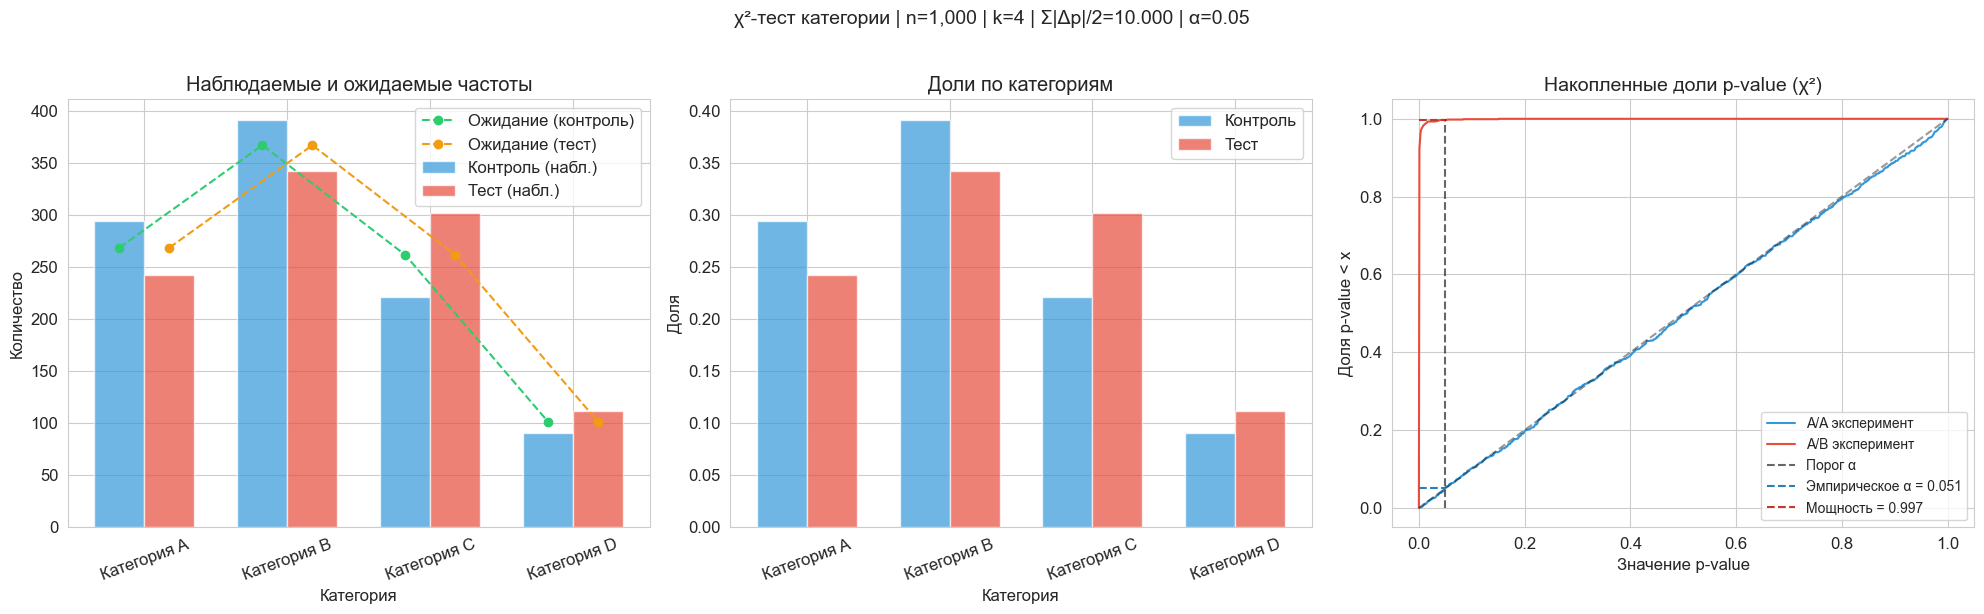

In [12]:
MatrixInt = NDArray[np.int64]


class ChiSquareResult(TypedDict):
    chi2_statistic: float
    p_value: float
    degrees_of_freedom: int
    expected_frequencies: FloatArray


@dataclass(frozen=True)
class ChiSquareScenario:
    """Параметры моделирования для χ²-теста независимости."""

    probabilities_ctrl: Sequence[float]
    probabilities_test: Sequence[float]
    sample_size: int
    simulations: int
    alpha: float
    seed: Optional[int] = None


def chi2_test(observed: MatrixInt) -> ChiSquareResult:
    """
    Выполняет χ²-тест на независимость категориальных распределений.
    """
    chi2, p_value, dof, expected = stats.chi2_contingency(observed)
    return ChiSquareResult(
        chi2_statistic=float(chi2),
        p_value=float(p_value),
        degrees_of_freedom=int(dof),
        expected_frequencies=expected,
    )


def generate_contingency_table(n_samples: int,
                               p_ctrl: Sequence[float],
                               p_test: Sequence[float],
                               seed: Optional[int] = None) -> MatrixInt:
    """Создаёт таблицу сопряжённости для двух групп."""
    rng = np.random.default_rng(seed)
    ctrl = rng.multinomial(n_samples, np.asarray(p_ctrl) / np.sum(p_ctrl))
    test = rng.multinomial(n_samples, np.asarray(p_test) / np.sum(p_test))
    return np.vstack([ctrl, test]).T


def run_chi2_simulation(n_sim: int,
                        n_samples: int,
                        p_ctrl: Sequence[float],
                        p_test: Sequence[float],
                        seed: Optional[int] = None) -> FloatArray:
    """Возвращает массив p-value из Монте-Карло для χ²-теста."""
    rng = np.random.default_rng(seed)
    p_values = np.empty(n_sim)
    p_ctrl = np.asarray(p_ctrl, dtype=float)
    p_test = np.asarray(p_test, dtype=float)

    for i in range(n_sim):
        ctrl = rng.multinomial(n_samples, p_ctrl / np.sum(p_ctrl))
        test = rng.multinomial(n_samples, p_test / np.sum(p_test))
        observed = np.vstack([ctrl, test]).T
        res = chi2_test(observed)
        p_values[i] = res['p_value']

    return p_values


def plot_chi2_results(observed: MatrixInt,
                      expected: FloatArray,
                      pvalues_aa: FloatArray,
                      pvalues_ab: FloatArray,
                      alpha: float,
                      subtitle: str,
                      categories: Optional[List[str]] = None) -> None:
    """Отрисовывает таблицу, относительные частоты и распределение p-value."""
    if categories is None:
        categories = [f'Категория {i + 1}' for i in range(observed.shape[0])]

    fig, (ax_counts, ax_relative, ax_pvalues) = plt.subplots(1, 3, figsize=(20, 6))
    x = np.arange(len(categories))
    width = 0.35

    ax_counts.bar(x - width / 2, observed[:, 0], width, label='Контроль (набл.)', color='#3498db', alpha=0.7)
    ax_counts.bar(x + width / 2, observed[:, 1], width, label='Тест (набл.)', color='#e74c3c', alpha=0.7)
    ax_counts.plot(x - width / 2, expected[:, 0], 'o--', color='#2ecc71', label='Ожидание (контроль)')
    ax_counts.plot(x + width / 2, expected[:, 1], 'o--', color='#f39c12', label='Ожидание (тест)')
    ax_counts.set_title('Наблюдаемые и ожидаемые частоты')
    ax_counts.set_xlabel('Категория')
    ax_counts.set_ylabel('Количество')
    ax_counts.set_xticks(x, categories, rotation=20)
    ax_counts.legend()

    rel_ctrl = observed[:, 0] / np.sum(observed[:, 0])
    rel_test = observed[:, 1] / np.sum(observed[:, 1])
    ax_relative.bar(x - width / 2, rel_ctrl, width, label='Контроль', color='#3498db', alpha=0.7)
    ax_relative.bar(x + width / 2, rel_test, width, label='Тест', color='#e74c3c', alpha=0.7)
    ax_relative.set_title('Доли по категориям')
    ax_relative.set_xlabel('Категория')
    ax_relative.set_ylabel('Доля')
    ax_relative.set_xticks(x, categories, rotation=20)
    ax_relative.legend()

    plot_pvalue_cdf(ax_pvalues, pvalues_aa, pvalues_ab, alpha, 'Накопленные доли p-value (χ²)')

    plt.suptitle(subtitle, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()


def run_chi2_analysis(params: ChiSquareScenario, categories: Optional[List[str]] = None) -> None:
    """Полный анализ: генерация таблицы, симуляции и визуализация."""
    observed = generate_contingency_table(
        n_samples=params.sample_size,
        p_ctrl=params.probabilities_ctrl,
        p_test=params.probabilities_test,
        seed=params.seed,
    )
    expected = chi2_test(observed)['expected_frequencies']

    pvals_aa = run_chi2_simulation(
        n_sim=params.simulations,
        n_samples=params.sample_size,
        p_ctrl=params.probabilities_ctrl,
        p_test=params.probabilities_ctrl,
        seed=params.seed,
    )

    pvals_ab = run_chi2_simulation(
        n_sim=params.simulations,
        n_samples=params.sample_size,
        p_ctrl=params.probabilities_ctrl,
        p_test=params.probabilities_test,
        seed=(params.seed + 1) if params.seed is not None else None,
    )

    effect = np.sum(np.abs(np.array(params.probabilities_test) - np.array(params.probabilities_ctrl))) / 2
    subtitle = (f'χ²-тест категории | n={params.sample_size:,} | k={len(params.probabilities_ctrl)} | '
                f'Σ|Δp|/2={effect:.3f} | α={params.alpha:.2f}')

    plot_chi2_results(
        observed=observed,
        expected=expected,
        pvalues_aa=pvals_aa,
        pvalues_ab=pvals_ab,
        alpha=params.alpha,
        subtitle=subtitle,
        categories=categories,
    )


scenario = ChiSquareScenario(
    probabilities_ctrl=[30, 40, 20, 10],
    probabilities_test=[25, 35, 30, 10],
    sample_size=1_000,
    simulations=1_000,
    alpha=0.05,
    seed=42,
)

category_labels = ['Категория A', 'Категория B', 'Категория C', 'Категория D']
run_chi2_analysis(scenario, categories=category_labels)

##### Mann–Whitney $U$ test

$U$-тест (тест Манна–Уитни) — это непараметрический критерий для сравнения двух независимых выборок. Он не требует нормальности данных и основан на ранжировании объединённой выборки.

$U$-тест Манна–Уитни применяют, когда необходимо проверить, что значения одной группы склонны быть больше значений другой. **Его нельзя использовать для проверки равенства средних или медиан** (подробно рассматривается [тут](https://habr.com/ru/companies/avito/articles/709596/)): значимый результат возможен и при равных средних, как мы увидим ниже.

**Предпосылки $U$-теста**  

* Независимость наблюдений внутри и между группами.
* Сравнивать медианы можно только при дополнительном предположении, что распределения отличаются лишь сдвигом и имеют одинаковую форму.
* Минимум порядкового уровня: достаточно уметь упорядочить (ранжировать) все наблюдения.

**Формулировки U-теста**

* **Нулевая гипотеза ($H_0$):** значения групп стохастически не различаются: $P(T > C) + \frac{1}{2}P(T = C) = \frac{1}{2}$. Часто её записывают более сильно: распределения совпадают, $F_T = F_C$.

* **Альтернативная гипотеза ($H_1$):** значения одной из групп склонны быть больше: $P(T > C) + \frac{1}{2}P(T = C) \neq \frac{1}{2}$.

* **$U$-статистика** считает, сколько пар «тест-контроль» упорядочены в пользу теста (совпадения считаются с весом 1/2):

$$
U = \sum_{i=1}^{N_T} \sum_{j=1}^{N_C} \left( \mathbf{1}\left[ T_i > C_j \right] + \tfrac{1}{2}\mathbf{1}\left[ T_i = C_j \right] \right)
$$

**Критерий принятия решения**

Решение, отвергать ли нулевую гипотезу, основывается на сравнении $U$-статистики с критическими значениями распределения статистики при верной $H_0$ (при больших выборках она приближается нормальным распределением) или на сравнении **p-value** с уровнем значимости $\alpha$.

**Метод p-value**:

  *   **p-value** — это вероятность получить наблюдаемые или более экстремальные результаты, если нулевая гипотеза верна.
  *   Если **p-value < $\alpha$**, нулевая гипотеза отвергается. Это означает, что наблюдаемые различия статистически значимы, и мы заключаем, что эффект существует.
  *   Если **p-value $\ge \alpha$**, нулевая гипотеза не отвергается. Это означает, что наблюдаемые различия не являются статистически значимыми, и мы не можем утверждать наличие эффекта.

Сценарий для нормального распределения:


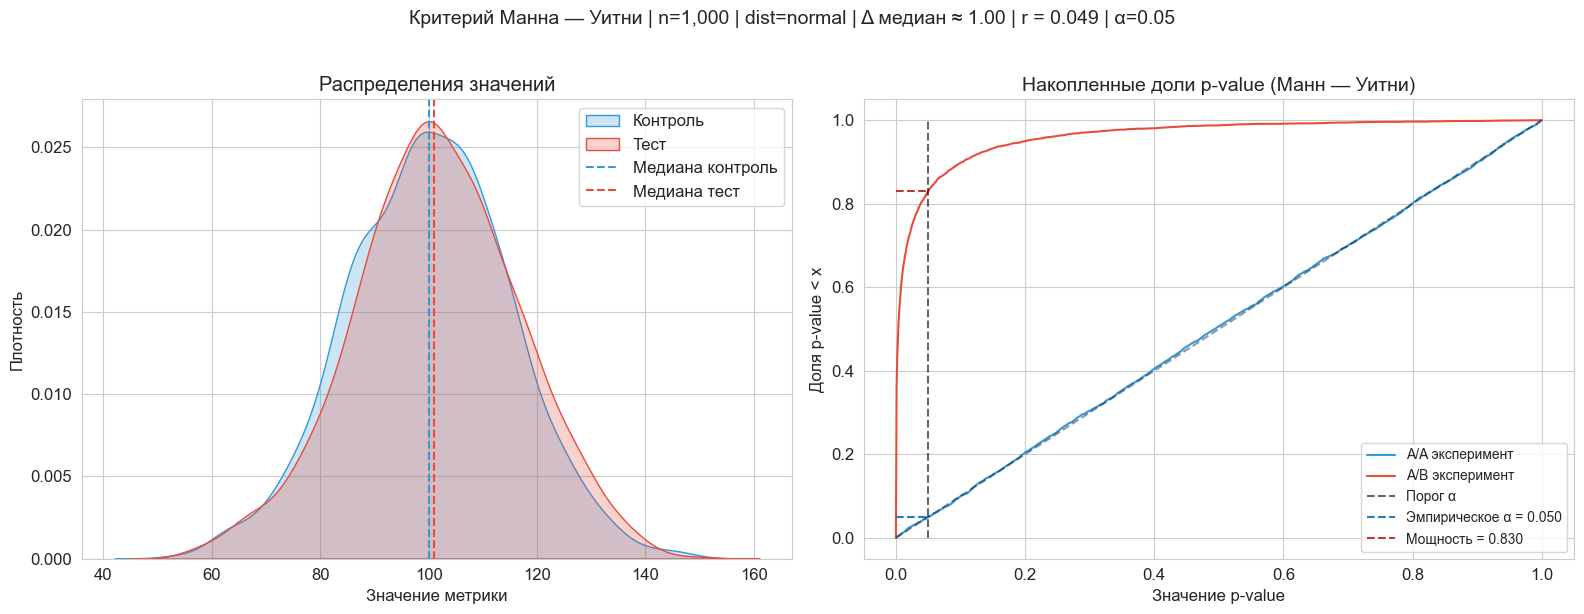


Сценарий для экспоненциального распределения:


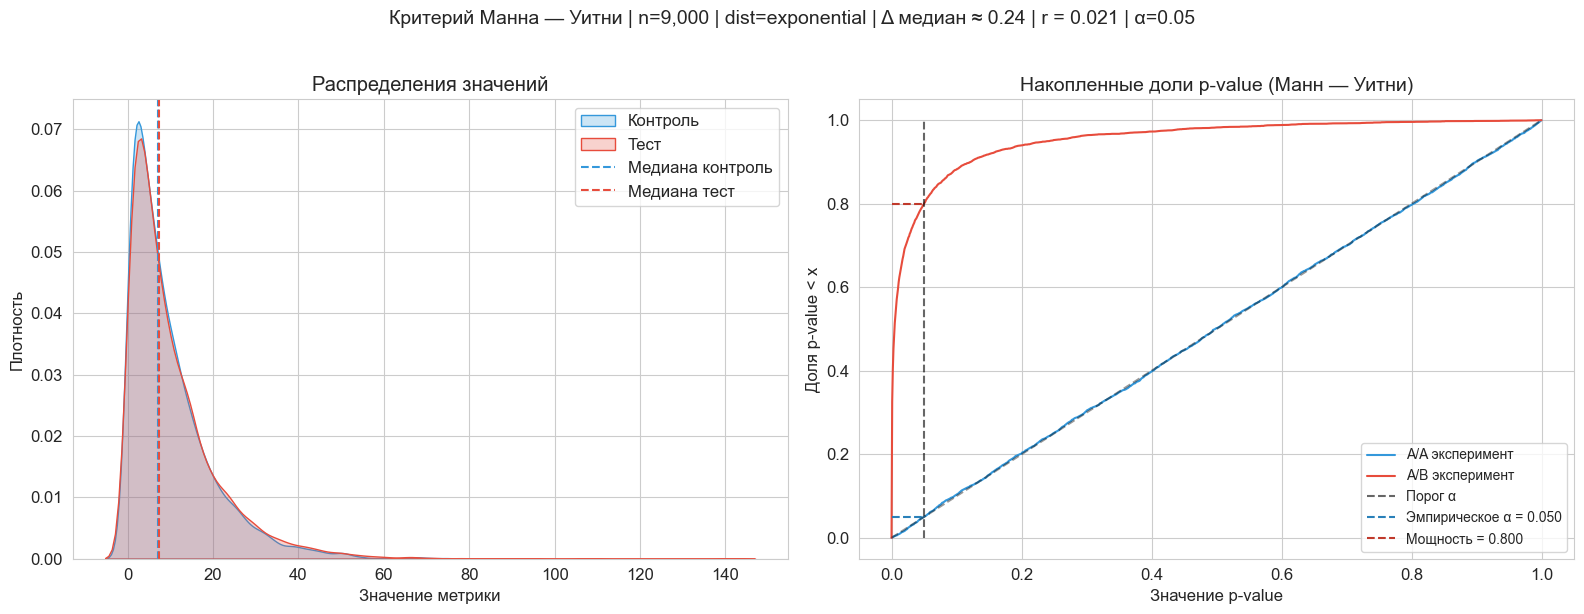

In [13]:
DistributionName = Literal['normal', 'exponential']


class MannWhitneyResult(TypedDict):
    u_statistic: float
    p_value: float
    effect_size: float
    median_control: float
    median_test: float


@dataclass(frozen=True)
class MannWhitneyScenario:
    """Параметры моделирования для критерия Манна — Уитни."""

    mu_ctrl: float
    mu_test: float
    sigma: float
    sample_size: int
    simulations: int
    alpha: float
    distribution: DistributionName = 'normal'
    seed: Optional[int] = None


def mann_whitney_u_test(control: FloatArray, test: FloatArray) -> MannWhitneyResult:
    """Возвращает статистику U, p-value, ранговую бисериальную корреляцию и медианы."""
    u_stat, p_value = stats.mannwhitneyu(control, test, alternative='two-sided')
    n_ctrl, n_test = len(control), len(test)
    effect_size = 1 - (2 * u_stat) / (n_ctrl * n_test)

    return MannWhitneyResult(
        u_statistic=float(u_stat),
        p_value=float(p_value),
        effect_size=float(effect_size),
        median_control=float(np.median(control)),
        median_test=float(np.median(test)),
    )


def generate_data(mu_ctrl: float,
                  mu_test: float,
                  sigma: float,
                  sample_size: int,
                  dist: DistributionName = 'normal',
                  seed: Optional[int] = None) -> tuple[FloatArray, FloatArray]:
    """Генерирует данные для выбранного распределения."""
    rng = np.random.default_rng(seed)

    if dist == 'normal':
        control = rng.normal(loc=mu_ctrl, scale=sigma, size=sample_size)
        test = rng.normal(loc=mu_test, scale=sigma, size=sample_size)
    elif dist == 'exponential':
        control = rng.exponential(scale=mu_ctrl, size=sample_size)
        test = rng.exponential(scale=mu_test, size=sample_size)
    else:
        raise ValueError('Поддерживаются только normal и exponential')

    return control, test


def run_u_test_simulation(n_sim: int,
                          sample_size: int,
                          mu_ctrl: float,
                          mu_test: float,
                          sigma: float,
                          dist: DistributionName = 'normal',
                          seed: Optional[int] = None) -> FloatArray:
    """Формирует распределение p-value для U-теста."""
    rng = np.random.default_rng(seed)
    p_values = np.empty(n_sim)

    for i in tqdm(range(n_sim), desc='Симуляции U-теста', leave=False):
        if dist == 'normal':
            ctrl = rng.normal(mu_ctrl, sigma, sample_size)
            test = rng.normal(mu_test, sigma, sample_size)
        else:
            ctrl = rng.exponential(mu_ctrl, sample_size)
            test = rng.exponential(mu_test, sample_size)

        res = mann_whitney_u_test(ctrl, test)
        p_values[i] = res['p_value']

    return p_values


def plot_u_test_results(control: FloatArray,
                        test: FloatArray,
                        pvalues_aa: FloatArray,
                        pvalues_ab: FloatArray,
                        alpha: float,
                        subtitle: str) -> None:
    """Краткое визуальное резюме для критерия Манна — Уитни."""
    fig, (ax_kde, ax_pvalues) = plt.subplots(1, 2, figsize=(16, 6))

    sns.kdeplot(control, color='#3498db', label='Контроль', ax=ax_kde, fill=True)
    sns.kdeplot(test, color='#e74c3c', label='Тест', ax=ax_kde, fill=True)
    ax_kde.axvline(np.median(control), color='#3498db', linestyle='--', label='Медиана контроль')
    ax_kde.axvline(np.median(test), color='#e74c3c', linestyle='--', label='Медиана тест')
    ax_kde.set_title('Распределения значений')
    ax_kde.set_xlabel('Значение метрики')
    ax_kde.set_ylabel('Плотность')
    ax_kde.legend()

    plot_pvalue_cdf(ax_pvalues, pvalues_aa, pvalues_ab, alpha, 'Накопленные доли p-value (Манн — Уитни)')

    plt.suptitle(subtitle, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()


def run_full_u_test_analysis(params: MannWhitneyScenario) -> None:
    """Выполняет полный сценарий анализа для U-теста."""
    control, test = generate_data(
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_test,
        sigma=params.sigma,
        sample_size=params.sample_size,
        dist=params.distribution,
        seed=params.seed,
    )

    test_result = mann_whitney_u_test(control, test)

    pvals_aa = run_u_test_simulation(
        n_sim=params.simulations,
        sample_size=params.sample_size,
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_ctrl,
        sigma=params.sigma,
        dist=params.distribution,
        seed=params.seed,
    )

    pvals_ab = run_u_test_simulation(
        n_sim=params.simulations,
        sample_size=params.sample_size,
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_test,
        sigma=params.sigma,
        dist=params.distribution,
        seed=(params.seed + 1) if params.seed is not None else None,
    )

    subtitle = (
        f'Критерий Манна — Уитни | n={params.sample_size:,} | dist={params.distribution} | '
        f'Δ медиан ≈ {test_result["median_test"] - test_result["median_control"]:.2f} | '
        f'r = {test_result["effect_size"]:.3f} | α={params.alpha:.2f}'
    )

    plot_u_test_results(
        control=control,
        test=test,
        pvalues_aa=pvals_aa,
        pvalues_ab=pvals_ab,
        alpha=params.alpha,
        subtitle=subtitle,
    )


scenario_normal = MannWhitneyScenario(
    mu_ctrl=100.0,
    mu_test=102.0,
    sigma=15.0,
    sample_size=1_000,
    simulations=5_000,
    alpha=0.05,
    distribution='normal',
    seed=666,
)

scenario_exponential = MannWhitneyScenario(
    mu_ctrl=10.0,
    mu_test=10.5,
    sigma=0.0,
    sample_size=9_000,
    simulations=5_000,
    alpha=0.05,
    distribution='exponential',
    seed=666,
)

print('Сценарий для нормального распределения:')
run_full_u_test_analysis(scenario_normal)

print('\nСценарий для экспоненциального распределения:')
run_full_u_test_analysis(scenario_exponential)

**Почему $U$-тест нельзя использовать для средних.** Возьмём две группы с **одинаковым** средним, но разной формой распределения: например, новая механика меняет разброс чеков, но не средний чек.

Средние в группах равны, но доля отвержений H0 у U-теста: 1.000
Доля отвержений H0 у t-теста Уэлча:                      0.051


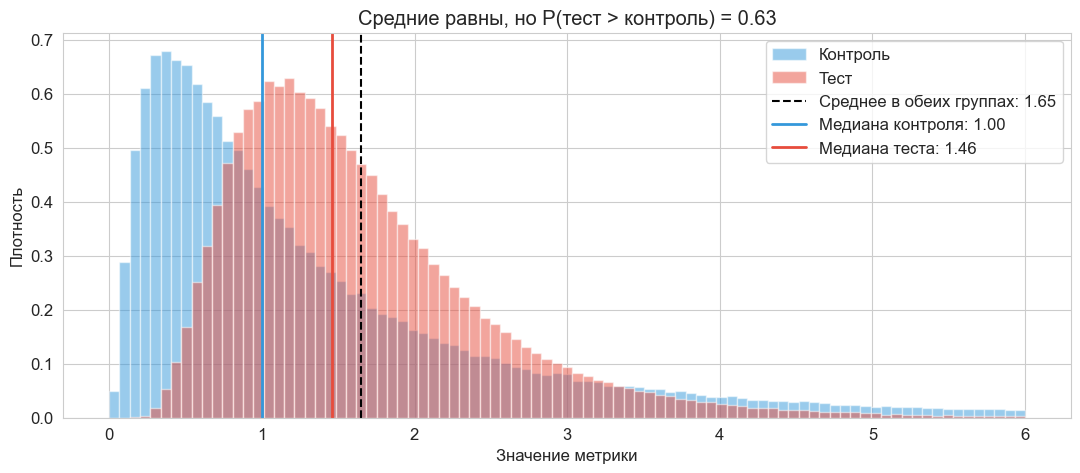

In [14]:
rng = np.random.default_rng(42)
n_users, n_iterations = 2_000, 1_000

# Логнормальные распределения с одинаковым средним exp(mu + sigma² / 2) = exp(0.5)
control_sigma, test_sigma = 1.0, 0.5
test_mu = 0.5 - test_sigma ** 2 / 2

rejected_u, rejected_t = 0, 0
for _ in range(n_iterations):
    control = rng.lognormal(0, control_sigma, n_users)
    test = rng.lognormal(test_mu, test_sigma, n_users)
    rejected_u += stats.mannwhitneyu(control, test).pvalue < 0.05
    rejected_t += stats.ttest_ind(control, test, equal_var=False).pvalue < 0.05

print(f'Средние в группах равны, но доля отвержений H0 у U-теста: {rejected_u / n_iterations:.3f}')
print(f'Доля отвержений H0 у t-теста Уэлча:                      {rejected_t / n_iterations:.3f}')

sample_control = rng.lognormal(0, control_sigma, 200_000)
sample_test = rng.lognormal(test_mu, test_sigma, 200_000)

fig, ax = plt.subplots(figsize=(13, 5))
bins = np.linspace(0, 6, 90)
ax.hist(sample_control, bins=bins, density=True, color='#3498db', alpha=0.5, label='Контроль')
ax.hist(sample_test, bins=bins, density=True, color='#e74c3c', alpha=0.5, label='Тест')
ax.axvline(np.exp(0.5), color='black', linestyle='--', label=f'Среднее в обеих группах: {np.exp(0.5):.2f}')
ax.axvline(np.median(sample_control), color='#3498db', linewidth=2, label=f'Медиана контроля: {np.median(sample_control):.2f}')
ax.axvline(np.median(sample_test), color='#e74c3c', linewidth=2, label=f'Медиана теста: {np.median(sample_test):.2f}')
ax.set_title(f'Средние равны, но P(тест > контроль) = {np.mean(sample_test > sample_control):.2f}')
ax.set_xlabel('Значение метрики')
ax.set_ylabel('Плотность')
ax.legend()
plt.show()

$U$-тест почти всегда находит различие: значения теста чаще оказываются больше значений контроля, хотя средние равны. Он реагирует на изменение формы распределения, а не среднего. Это не ошибка критерия: он честно проверяет другую гипотезу. Но отчитываться таким тестом о росте среднего чека нельзя.

##### Бутстреп

Для метрик без готового критерия подходит бутстреп. Он почти универсален, но не всемогущ: например, он плохо работает для экстремальных статистик и при очень тяжёлых хвостах.

Общий пайплайн:

* Много раз:
  1. Делаем подвыборки с возвращением.
  2. Считаем метрики из полученных выборок.

* На основе полученных статистик делаем вывод, отвергать ли гипотезу.

Методологию и разные виды бутстрепа мы подробно рассматривали в [лекции 1.01](https://github.com/Alberelloo/Hypothesis-Testing-Course/blob/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/01.%20%D0%A1%D1%82%D0%B0%D1%82%D0%B8%D1%81%D1%82%D0%B8%D0%BA%D0%B0%20%D0%B2%20Python.%20%D0%91%D1%83%D1%82%D1%81%D1%82%D1%80%D0%B0%D0%BF/lecture.ipynb). Там же описан способ получить p-value: перед ресэмплированием группы сдвигаются к общему среднему, чтобы выполнялась $H_0$. Просто объединять группы нельзя: так проверяется равенство всего распределения, а не средних, и при разных дисперсиях ошибка первого рода сильно растёт.

=== Сценарий для нормального распределения ===


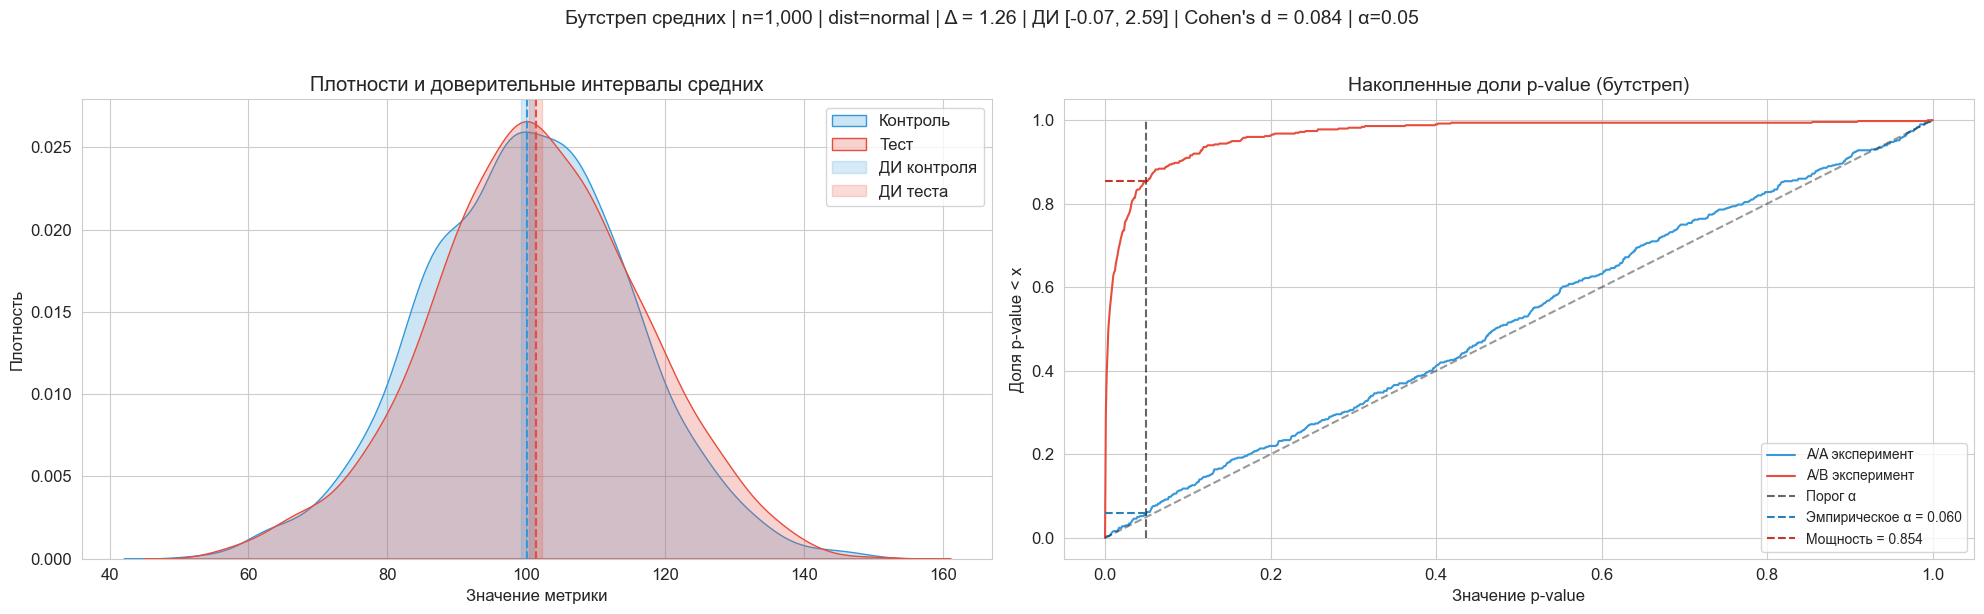


=== Сценарий для экспоненциального распределения ===


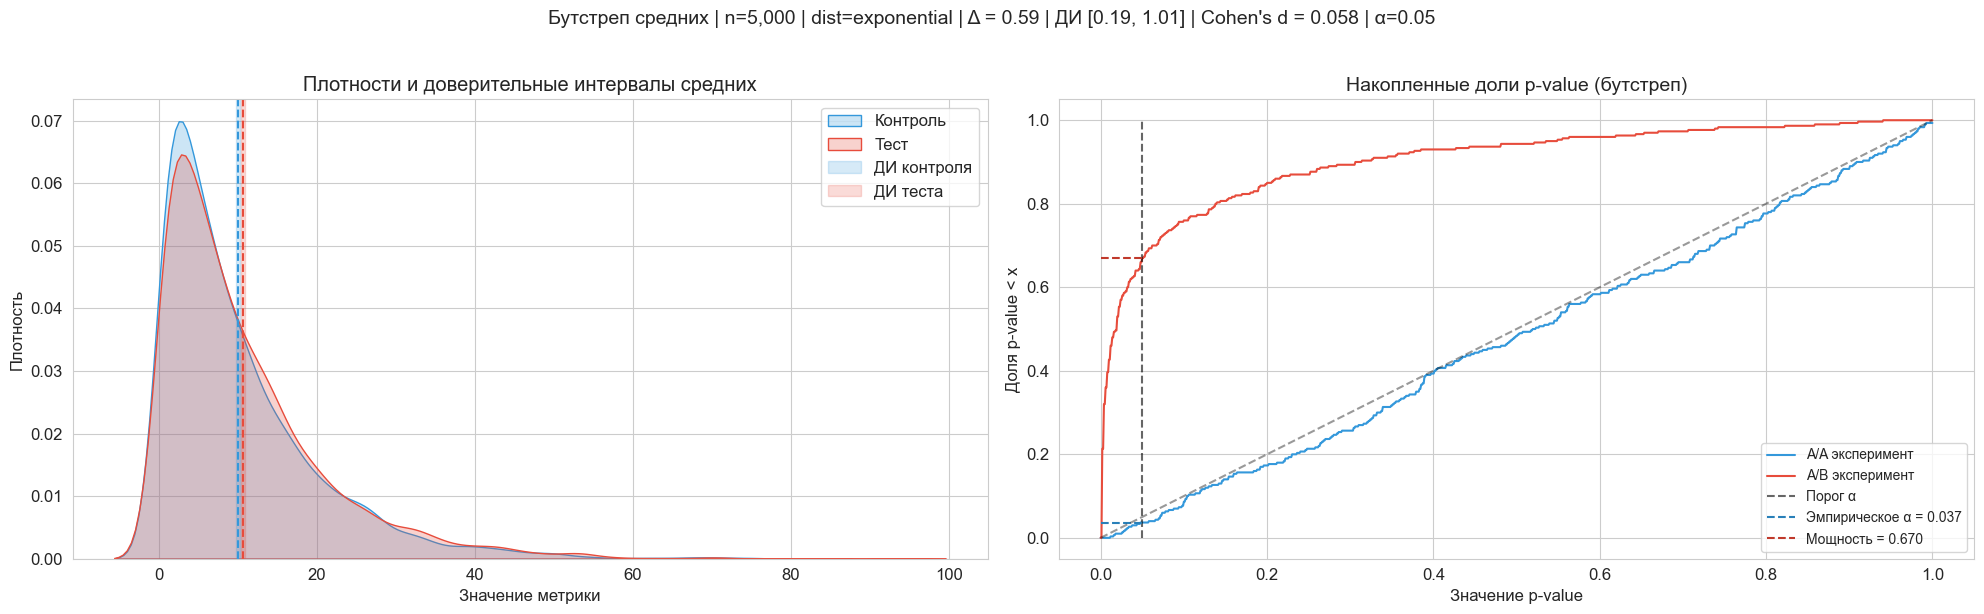

In [15]:
DistributionName = Literal['normal', 'exponential', 'uniform']


class BootstrapResult(TypedDict):
    difference: float
    ci_lower: float
    ci_upper: float
    p_value: float
    mean_control: float
    mean_test: float
    n_resamples: int


@dataclass(frozen=True)
class BootstrapScenario:
    """Параметры моделирования для бутстрепа средних."""

    mu_ctrl: float
    mu_test: float
    sigma: float
    sample_size: int
    simulations: int
    n_resamples: int
    alpha: float
    distribution: DistributionName = 'normal'
    seed: Optional[int] = None


def bootstrap_compare_means(control: FloatArray,
                            test: FloatArray,
                            n_resamples: int = 2_000,
                            confidence_level: float = 0.95,
                            seed: Optional[int] = None) -> BootstrapResult:
    """Оценивает разность средних: перцентильный бутстреп-ДИ и двусторонний p-value."""
    rng = np.random.default_rng(seed)
    n_ctrl, n_test = len(control), len(test)
    mean_ctrl, mean_test = float(np.mean(control)), float(np.mean(test))
    observed_diff = mean_test - mean_ctrl

    def resampled_means(data: FloatArray) -> FloatArray:
        # Матрица из n_resamples выборок: одна строка — одна бутстреп-выборка
        return data[rng.integers(0, len(data), (n_resamples, len(data)))].mean(axis=1)

    # Доверительный интервал: ресэмплируем исходные группы
    diffs = resampled_means(test) - resampled_means(control)
    alpha = 1 - confidence_level
    ci_lower, ci_upper = np.quantile(diffs, [alpha / 2, 1 - alpha / 2])

    # P-value: сдвигаем группы к общему среднему, чтобы выполнялась H₀
    pooled_mean = (n_ctrl * mean_ctrl + n_test * mean_test) / (n_ctrl + n_test)
    diffs_null = resampled_means(test - mean_test + pooled_mean) - resampled_means(control - mean_ctrl + pooled_mean)
    p_value = float((np.sum(np.abs(diffs_null) >= abs(observed_diff)) + 1) / (n_resamples + 1))

    return BootstrapResult(
        difference=observed_diff,
        ci_lower=float(ci_lower),
        ci_upper=float(ci_upper),
        p_value=p_value,
        mean_control=mean_ctrl,
        mean_test=mean_test,
        n_resamples=n_resamples,
    )


def generate_data(mu_ctrl: float,
                  mu_test: float,
                  sigma: float,
                  sample_size: int,
                  dist: DistributionName = 'normal',
                  seed: Optional[int] = None) -> tuple[FloatArray, FloatArray]:
    """Создаёт данные для выбранного распределения."""
    rng = np.random.default_rng(seed)

    if dist == 'normal':
        control = rng.normal(mu_ctrl, sigma, sample_size)
        test = rng.normal(mu_test, sigma, sample_size)
    elif dist == 'exponential':
        control = rng.exponential(mu_ctrl, sample_size)
        test = rng.exponential(mu_test, sample_size)
    elif dist == 'uniform':
        control = rng.uniform(mu_ctrl, mu_ctrl + sigma, sample_size)
        test = rng.uniform(mu_test, mu_test + sigma, sample_size)
    else:
        raise ValueError('Поддерживаются распределения normal/exponential/uniform')

    return control, test


def run_bootstrap_simulation(n_sim: int,
                             sample_size: int,
                             mu_ctrl: float,
                             mu_test: float,
                             sigma: float,
                             n_resamples: int,
                             dist: DistributionName = 'normal',
                             seed: Optional[int] = None) -> FloatArray:
    """Возвращает массив p-value из бутстреп-теста."""
    rng = np.random.default_rng(seed)
    p_values = np.empty(n_sim)

    for i in tqdm(range(n_sim), desc='Симуляции бутстрепа', leave=False):
        control, test = generate_data(
            mu_ctrl=mu_ctrl,
            mu_test=mu_test,
            sigma=sigma,
            sample_size=sample_size,
            dist=dist,
            seed=rng.integers(0, 1 << 32),
        )
        res = bootstrap_compare_means(control, test, n_resamples=n_resamples, seed=rng.integers(0, 1 << 32))
        p_values[i] = res['p_value']

    return p_values


def plot_bootstrap_results(control: FloatArray,
                           test: FloatArray,
                           pvalues_aa: FloatArray,
                           pvalues_ab: FloatArray,
                           alpha: float,
                           subtitle: str) -> None:
    """Комбинированная визуализация распределений и p-value."""
    fig, (ax_dist, ax_pvalues) = plt.subplots(1, 2, figsize=(20, 6))

    sns.kdeplot(control, color='#3498db', label='Контроль', ax=ax_dist, fill=True)
    sns.kdeplot(test, color='#e74c3c', label='Тест', ax=ax_dist, fill=True)

    def _mean_ci(data: FloatArray) -> tuple[float, float, float]:
        half_width = 1.96 * np.std(data, ddof=1) / np.sqrt(len(data))
        return float(np.mean(data)), float(np.mean(data) - half_width), float(np.mean(data) + half_width)

    mean_ctrl, ci_ctrl_low, ci_ctrl_high = _mean_ci(control)
    mean_test, ci_test_low, ci_test_high = _mean_ci(test)

    ax_dist.axvspan(ci_ctrl_low, ci_ctrl_high, color='#3498db', alpha=0.2, label='ДИ контроля')
    ax_dist.axvspan(ci_test_low, ci_test_high, color='#e74c3c', alpha=0.2, label='ДИ теста')
    ax_dist.axvline(mean_ctrl, color='#3498db', linestyle='--')
    ax_dist.axvline(mean_test, color='#e74c3c', linestyle='--')
    ax_dist.set_title('Плотности и доверительные интервалы средних')
    ax_dist.set_xlabel('Значение метрики')
    ax_dist.set_ylabel('Плотность')
    ax_dist.legend()

    plot_pvalue_cdf(ax_pvalues, pvalues_aa, pvalues_ab, alpha, 'Накопленные доли p-value (бутстреп)')

    plt.suptitle(subtitle, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()


def run_full_bootstrap_analysis(params: BootstrapScenario) -> None:
    """Полный сценарий для бутстрепа средних."""
    control, test = generate_data(
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_test,
        sigma=params.sigma,
        sample_size=params.sample_size,
        dist=params.distribution,
        seed=params.seed,
    )

    summary = bootstrap_compare_means(
        control,
        test,
        n_resamples=params.n_resamples,
        confidence_level=1 - params.alpha,
        seed=params.seed,
    )

    pvals_aa = run_bootstrap_simulation(
        n_sim=params.simulations,
        sample_size=params.sample_size,
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_ctrl,
        sigma=params.sigma,
        n_resamples=params.n_resamples,
        dist=params.distribution,
        seed=params.seed,
    )

    pvals_ab = run_bootstrap_simulation(
        n_sim=params.simulations,
        sample_size=params.sample_size,
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_test,
        sigma=params.sigma,
        n_resamples=params.n_resamples,
        dist=params.distribution,
        seed=(params.seed + 1) if params.seed is not None else None,
    )

    pooled_std = np.sqrt((np.var(control) + np.var(test)) / 2)
    effect_size = summary['difference'] / pooled_std if pooled_std else 0.0
    subtitle = (
        f'Бутстреп средних | n={params.sample_size:,} | dist={params.distribution} | '
        f'Δ = {summary["difference"]:.2f} | ДИ [{summary["ci_lower"]:.2f}, {summary["ci_upper"]:.2f}] | '
        f"Cohen's d = {effect_size:.3f} | α={params.alpha:.2f}"
    )

    plot_bootstrap_results(
        control=control,
        test=test,
        pvalues_aa=pvals_aa,
        pvalues_ab=pvals_ab,
        alpha=params.alpha,
        subtitle=subtitle,
    )


scenario_normal = BootstrapScenario(
    mu_ctrl=100.0,
    mu_test=102.0,
    sigma=15.0,
    sample_size=1_000,
    simulations=500,
    n_resamples=1_000,
    alpha=0.05,
    distribution='normal',
    seed=666,
)

scenario_exponential = BootstrapScenario(
    mu_ctrl=10.0,
    mu_test=10.5,
    sigma=0.0,
    sample_size=5_000,
    simulations=300,
    n_resamples=500,
    alpha=0.05,
    distribution='exponential',
    seed=666,
)

print('=== Сценарий для нормального распределения ===')
run_full_bootstrap_analysis(scenario_normal)

print('\n=== Сценарий для экспоненциального распределения ===')
run_full_bootstrap_analysis(scenario_exponential)

### Проверка корректности критерия

Как видим, каждый критерий имеет свои предпосылки для своего применения. Если они будут нарушены, то критерий не будет гарантированно держать ошибки 1 и 2 рода в рамках номинально заданных. Таким образом, перед началом A/B теста важно не только выбрать критерий, но и проверить корректность его применения.

К сожалению, не все предпосылки можно как-либо проверить, из-за чего могут появляться сомнения о применимости статистического критерия на данных. Поэтому на практике проверяют не предпосылки, а сам критерий на исторических данных. Для этого проводят серию A/A и A/B тестов на части исторических данных.

* **A/A тест**

  **A/A тест** - это тест, в котором никакой группе не даётся эффекта (поэтому A/A), из-за чего фактически будет верна нулевая гипотеза $H_0$. Проверяя критерий на этих группах мы можем оценить ошибку 1 рода.

  *  Много-много раз:
      1. Берем исторические данные на тот же период, который мы хотим держать тест;
      2. Случайным образом делим данные на тестовую и контрольную группу;
      3. Применяем выбранный статистический критерий;
  * Считаем, в скольких случаях статистический критерий отверг $H_0$ - это число и будет оценкой ошибки 1 рода этого критерия на ваших данных.

* **A/B тест**

  **A/B тест** - это тест, в котором какой-то группе даётся номинальный эффект, из-за чего фактически будет верна альтернативная гипотеза $H_1$. Проверяя критерий на этих группах мы можем оценить ошибку 2 рода и мощность.

  *  Много-много раз:
      1. Берем исторические данные на тот же период, который мы хотим держать тест;
      2. Случайным образом делим данные на тестовую и контрольную группу;
      3. Назначаем тестовой группе воздействие, равное вашему MDE;
      4. Применяем выбранный статистический критерий;
  * Считаем, в скольких случаях статистический критерий отверг $H_0$ - это число и будет оценкой мощности этого критерия на ваших данных.

Так как цель проведения A/A и A/B тестов - оценить, как будет вести себя выбранный критерий на реальных данных, то мы делаем предположение, что те условия, в которых мы проводим эти тесты, совпадают с тем, что мы только планируем запускать. Это довольно тонкий момент, т.к.:
1. Не всегда будут исторические данные (например супер молодой продукт)
2. Исторические данные отличаются (data-drift) от тех, которые мы получим (например, исторические данные собраны в период праздников или волны хайпа, сместившей спрос на товар X)

В первом случае остаётся опираться на экспертные предположения и проверять их выполнение постфактум.
Во втором случае мы можем попытаться выбрать наиболее похожий исторический период к нашему и проводить тесты на нём.


Сводка по ошибкам:
Ошибка I рода: 0.0454 (CI: 0.0396, 0.0512)
Ошибка II рода: 0.2082 (CI: 0.1969, 0.2195)
Мощность: 0.7918 (CI: 0.7805, 0.8031)


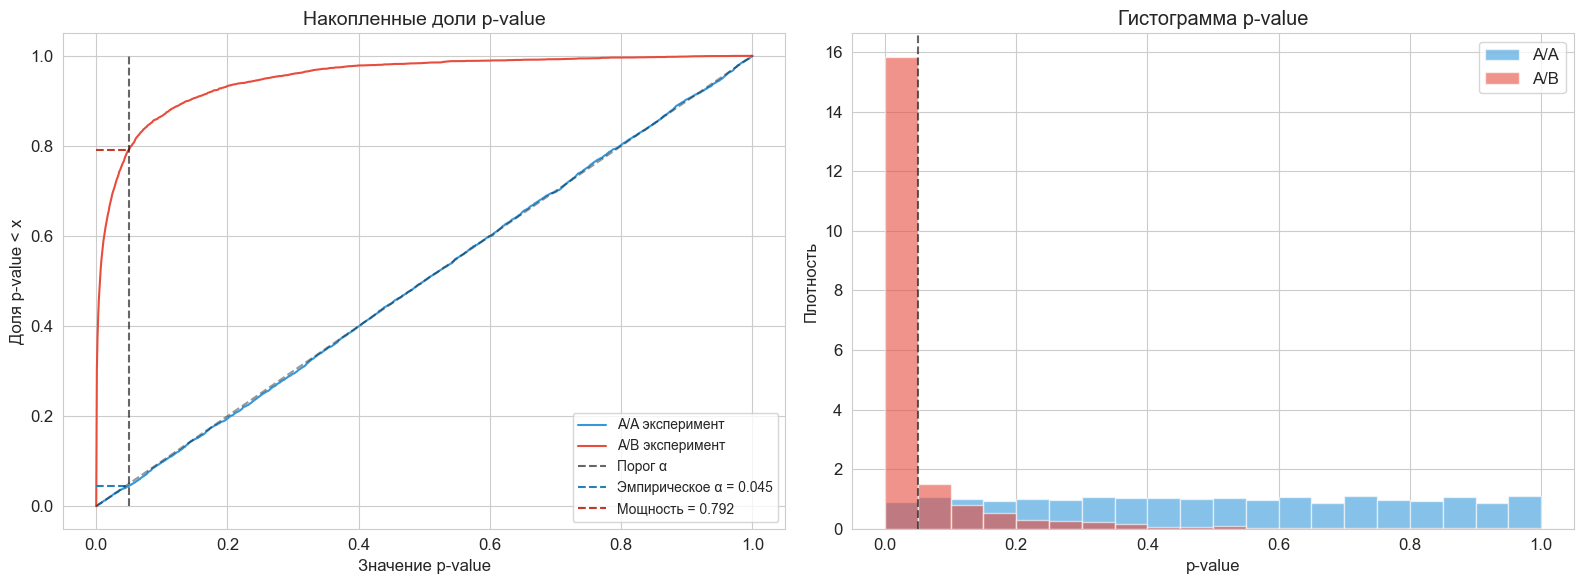

In [16]:
sns_colors = ['#3498db', '#e74c3c']



@dataclass(frozen=True)
class HistoricalSimulationScenario:
    """Параметры моделирования для оценки ошибок A/A и A/B."""

    historical_mean: float = 2_500.0
    historical_std: float = 800.0
    sample_size: int = 1_500
    alpha: float = 0.05
    beta: float = 0.2
    effect: float = 82.0  # MDE при заданных n, σ, α и β
    simulations: int = 5_000
    seed: int = 42


def generate_historical_data(mu: float,
                             std: float,
                             n_samples: int,
                             seed: int) -> FloatArray:
    """Генерирует «историческое» распределение метрики."""
    rng = np.random.default_rng(seed)
    return rng.normal(mu, std, n_samples)


def run_simulations(data: FloatArray,
                    sample_size: int,
                    effect: float,
                    n_iter: int,
                    seed: int) -> Tuple[FloatArray, FloatArray]:
    """Выполняет A/A и A/B симуляции с использованием исторических данных."""
    rng = np.random.default_rng(seed)
    pvalues_aa = np.empty(n_iter)
    pvalues_ab = np.empty(n_iter)

    for i in tqdm(range(n_iter), desc='A/A и A/B симуляции', leave=False):
        # Группы не должны пересекаться: один пользователь не может быть в двух группах сразу
        shuffled = rng.permutation(data)
        control_aa, test_aa = shuffled[:sample_size], shuffled[sample_size:2 * sample_size]
        pvalues_aa[i] = stats.ttest_ind(control_aa, test_aa, equal_var=False).pvalue

        shuffled = rng.permutation(data)
        control_ab, test_ab = shuffled[:sample_size], shuffled[sample_size:2 * sample_size] + effect
        pvalues_ab[i] = stats.ttest_ind(control_ab, test_ab, equal_var=False).pvalue

    return pvalues_aa, pvalues_ab


def _bernoulli_ci(p_hat: float, n: int, alpha: float) -> Tuple[float, float]:
    """Асимптотический интервал Вальда для вероятности."""
    z = stats.norm.ppf(1 - alpha / 2)
    std = np.sqrt(p_hat * (1 - p_hat) / n)
    return p_hat - z * std, p_hat + z * std


def calculate_error_rates(pvalues_aa: FloatArray,
                          pvalues_ab: FloatArray,
                          alpha: float) -> Dict[str, Tuple[float, Tuple[float, float]]]:
    """Возвращает оценки ошибок I/II рода и мощности с доверительными интервалами."""
    first_type = float(np.mean(pvalues_aa < alpha))
    second_type = float(np.mean(pvalues_ab >= alpha))
    power = 1 - second_type

    return {
        'first_type_error': (first_type, _bernoulli_ci(first_type, len(pvalues_aa), alpha)),
        'second_type_error': (second_type, _bernoulli_ci(second_type, len(pvalues_ab), alpha)),
        'power': (power, _bernoulli_ci(power, len(pvalues_ab), alpha)),
    }


def plot_results(pvalues_aa: FloatArray, pvalues_ab: FloatArray, alpha: float) -> None:
    """Строит CDF и гистограмму p-value для A/A и A/B симуляций."""
    fig, (ax_cdf, ax_hist) = plt.subplots(1, 2, figsize=(16, 6))

    plot_pvalue_cdf(ax_cdf, pvalues_aa, pvalues_ab, alpha, 'Накопленные доли p-value')

    bins = np.linspace(0, 1, 21)
    ax_hist.hist(pvalues_aa, bins=bins, color=sns_colors[0], alpha=0.6, density=True, label='A/A')
    ax_hist.hist(pvalues_ab, bins=bins, color=sns_colors[1], alpha=0.6, density=True, label='A/B')
    ax_hist.axvline(alpha, color='k', linestyle='--', alpha=0.6)
    ax_hist.set_title('Гистограмма p-value')
    ax_hist.set_xlabel('p-value')
    ax_hist.set_ylabel('Плотность')
    ax_hist.legend()

    plt.tight_layout()
    plt.show()


def print_error_report(error_rates: Dict[str, Tuple[float, Tuple[float, float]]]) -> None:
    """Выводит сводку по ошибкам и мощности."""
    print('\nСводка по ошибкам:')
    err1, ci1 = error_rates['first_type_error']
    err2, ci2 = error_rates['second_type_error']
    power, ci_power = error_rates['power']
    print(f'Ошибка I рода: {err1:.4f} (CI: {ci1[0]:.4f}, {ci1[1]:.4f})')
    print(f'Ошибка II рода: {err2:.4f} (CI: {ci2[0]:.4f}, {ci2[1]:.4f})')
    print(f'Мощность: {power:.4f} (CI: {ci_power[0]:.4f}, {ci_power[1]:.4f})')


scenario = HistoricalSimulationScenario()

historical_data = generate_historical_data(
    mu=scenario.historical_mean,
    std=scenario.historical_std,
    n_samples=10_000,
    seed=scenario.seed,
)

pvalues_aa, pvalues_ab = run_simulations(
    data=historical_data,
    sample_size=scenario.sample_size,
    effect=scenario.effect,
    n_iter=scenario.simulations,
    seed=scenario.seed,
)

error_rates = calculate_error_rates(
    pvalues_aa=pvalues_aa,
    pvalues_ab=pvalues_ab,
    alpha=scenario.alpha,
)

print_error_report(error_rates)
plot_results(pvalues_aa, pvalues_ab, scenario.alpha)

**Распределение p-value**

Если тест контролирует вероятность ошибки первого рода при любом заданном уровне значимости $\alpha$, то формально это можно записать так:

$$
\mathbb{P}(p\text{-value} < \alpha | H_0) = \alpha \quad  \forall \alpha \in [0, 1]
$$

Заметим, что в левой части равенства записано выражение для функции распределения p-value. Из равенства следует, что функция распределения p-value в точке X равна X для любого X от 0 до 1. Эта функция распределения является функцией распределения равномерного распределения от 0 до 1. Мы показали, что критерий с непрерывной статистикой контролирует вероятность ошибки первого рода на заданном уровне для любого уровня значимости тогда и только тогда, когда при верности нулевой гипотезы p-value распределено равномерно от 0 до 1.

При верности нулевой гипотезы p-value должно быть распределено равномерно. А как должно быть распределено p-value при верности альтернативной гипотезы? Из условия для вероятности ошибки второго рода $\mathbb{P}(p\text{-value} \geq \alpha | H_1) = \beta$ следует, что $\mathbb{P}(p\text{-value} < \alpha | H_1) = 1 - \beta$.

Получается, график функции распределения p-value при верности альтернативной гипотезы должен проходить через точку [$\alpha$, $1 - \beta$], где $\alpha$ и $\beta$– допустимые вероятности ошибок конкретного эксперимента.

## Основные проблемы тестов

A/B-тестирование – это мощный инструмент для принятия решений, но его корректность сильно зависит от правильного применения статистических методов и учета потенциальных проблем. Рассмотрим типичные проблемы и возможные способы их решения.

### Проблема подглядывания (peeking problem)

Предположим, что где-то в середине эксперимента мы посмотрели на p-value и увидели, что оно уже несколько дней находится ниже запланированного $\alpha$. Может быть, есть смысл досрочно остановить эксперимент и заявить, что альтернативная гипотеза верна?

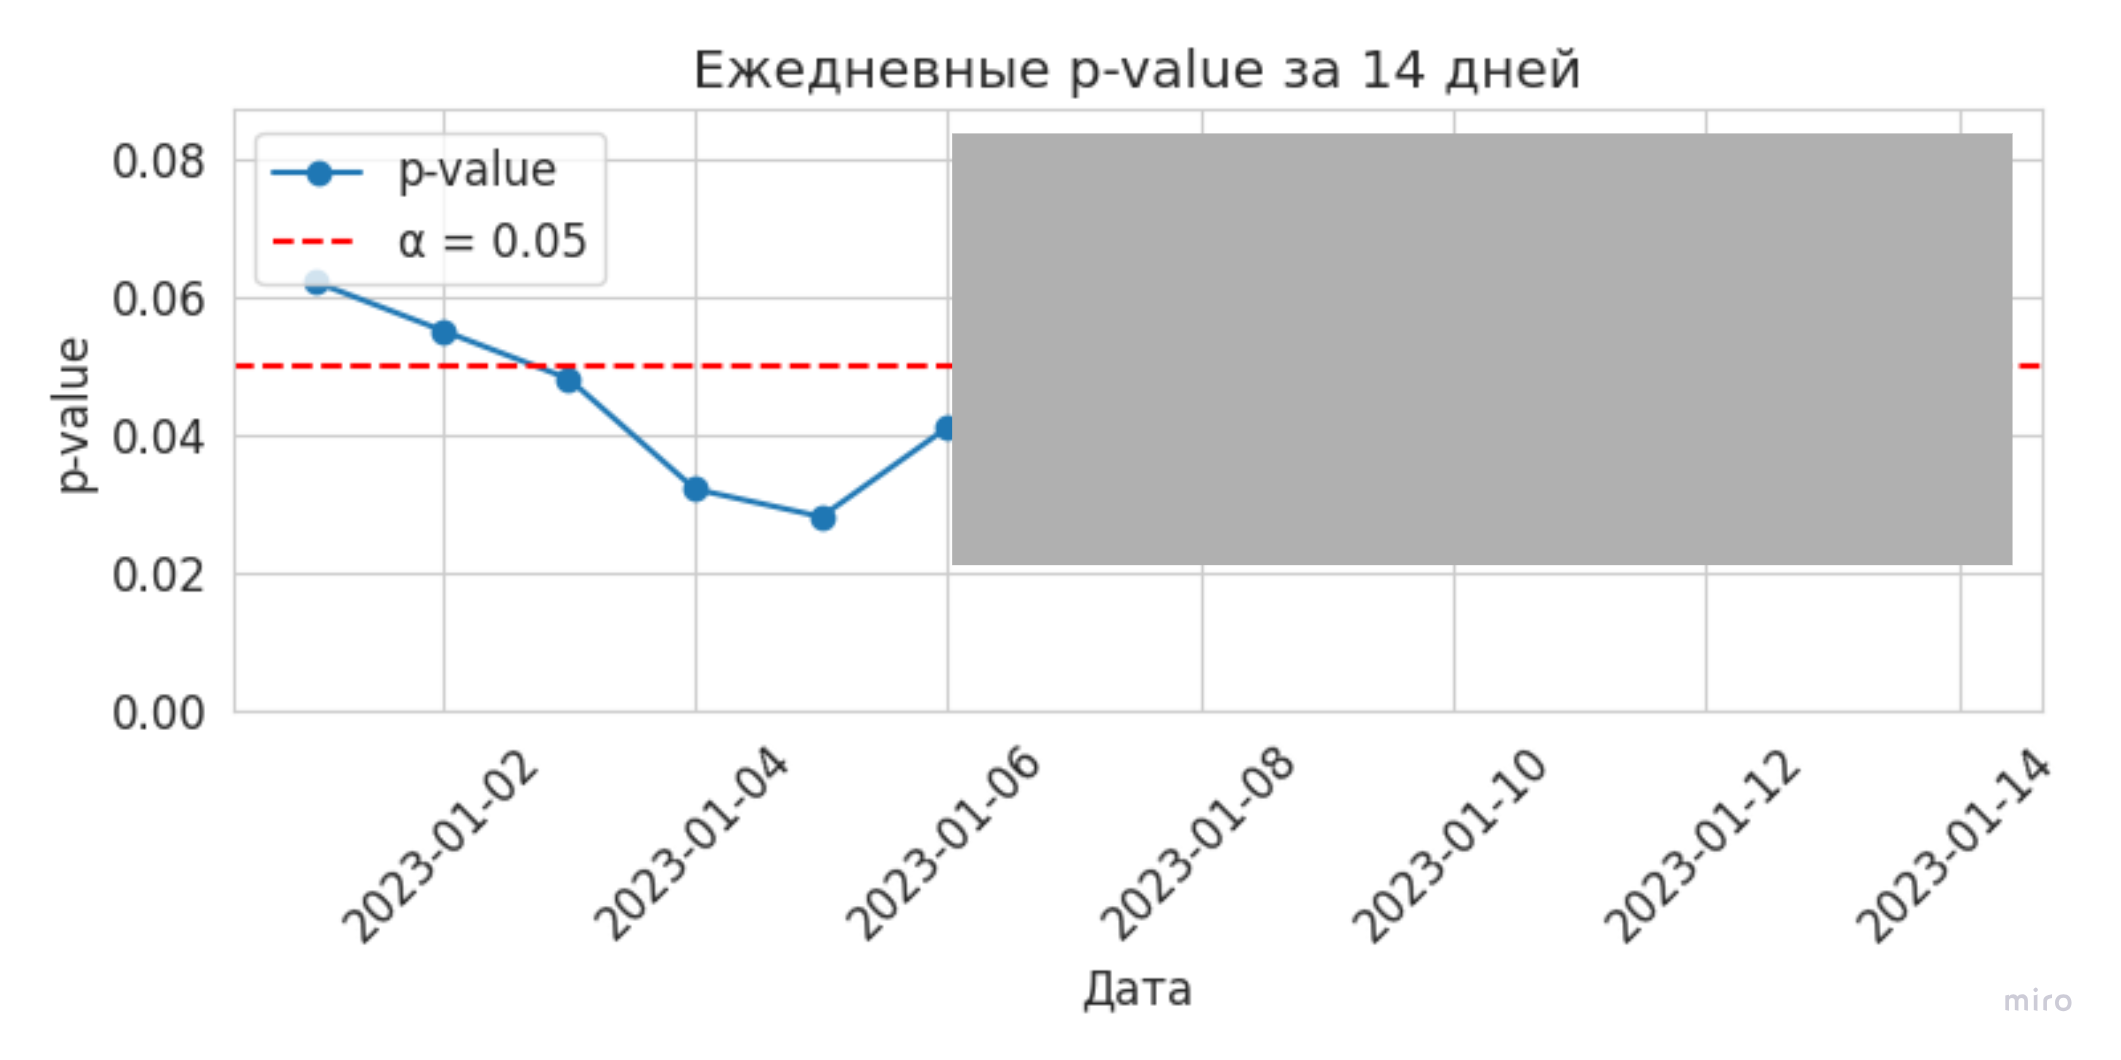

Интуитивно можно привести 2 аргумента **против** решения досрочной остановки теста:

1. Посчитанное p-value зависит от случайно набранной выборки, то есть само является случайной величиной. Поэтому к концу теста оно может сдвинуться обратно и закончить выше порога.

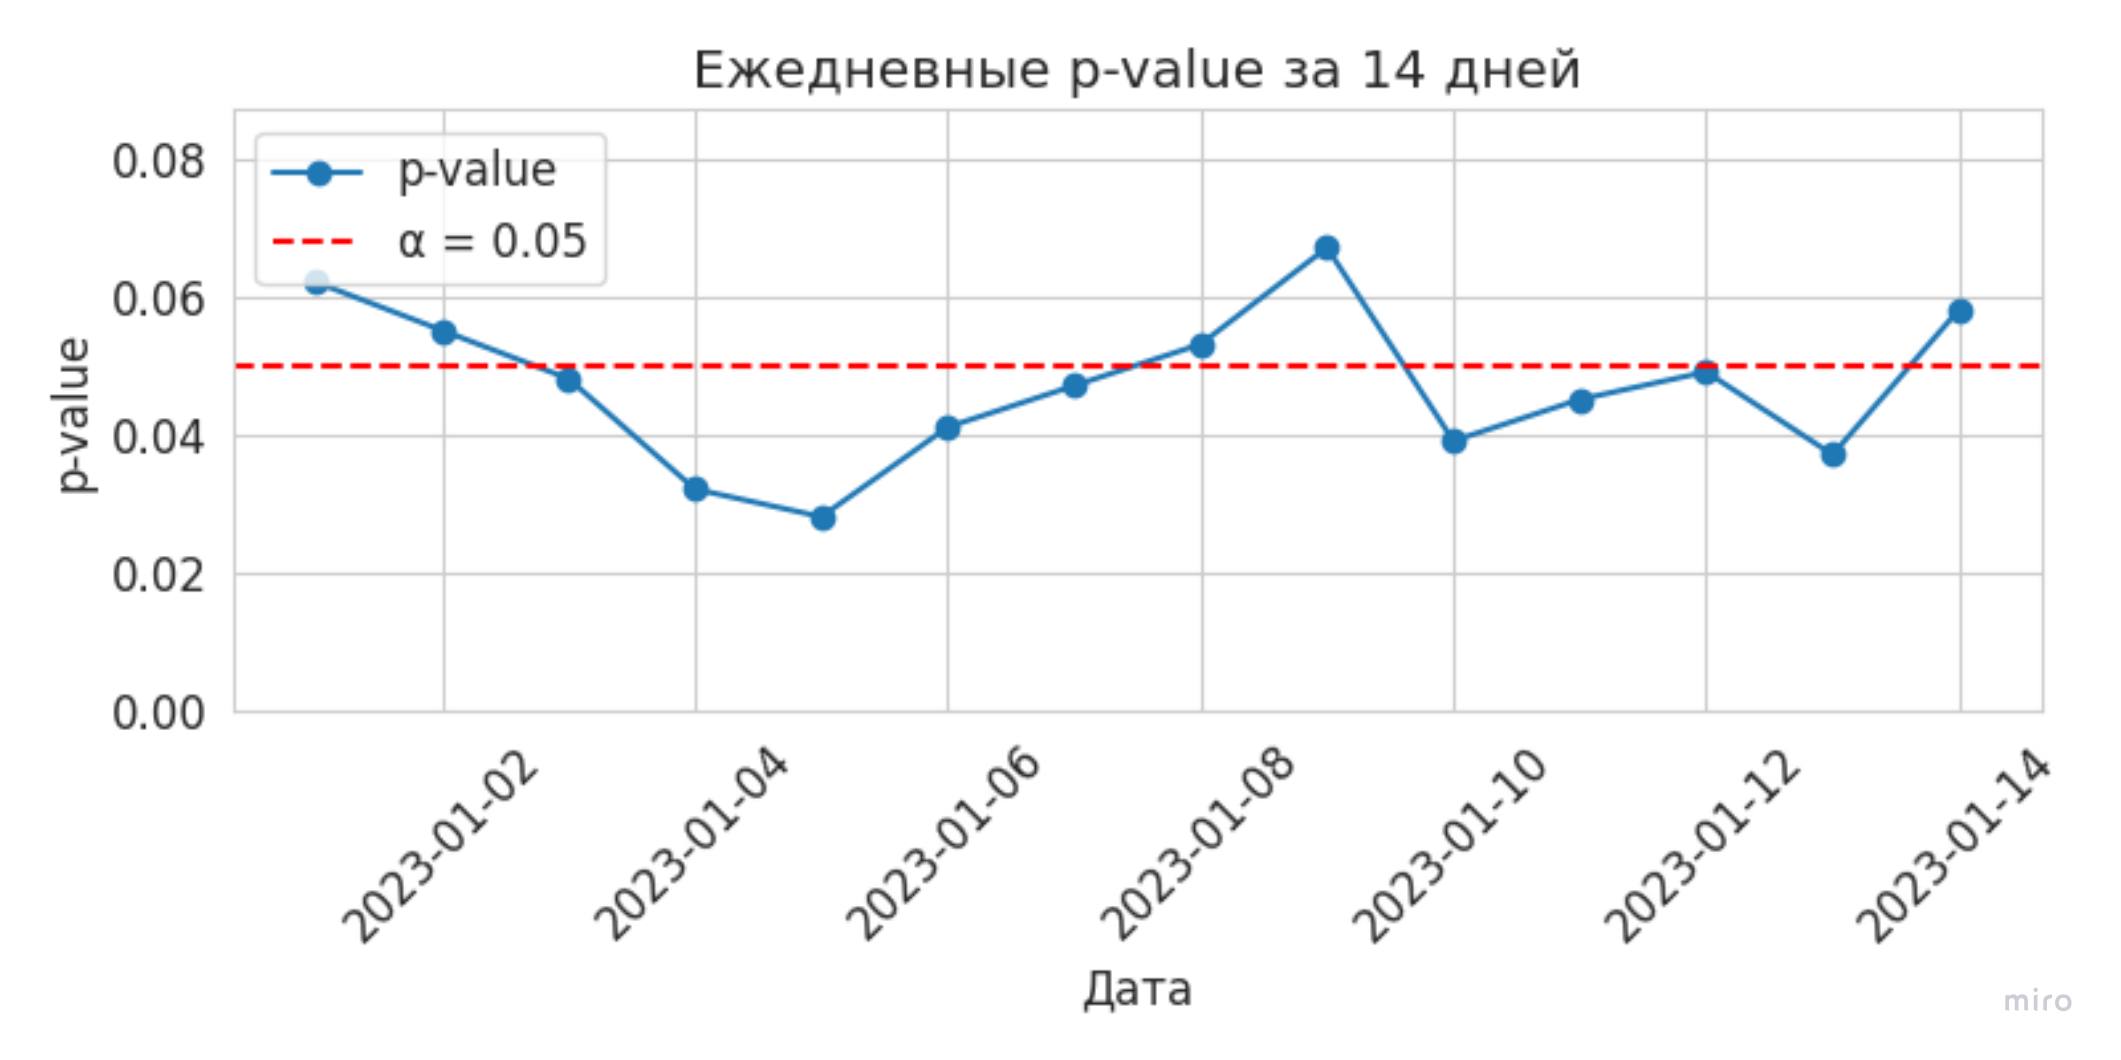

2. Гарантии критерия рассчитаны на заранее фиксированную выборку. Если останавливать тест по результату промежуточного взгляда, ошибки 1 и 2 рода перестают контролироваться на номинальном уровне.

Многократная проверка результатов A/B-теста до достижения заранее определенного размера выборки или окончания фиксированного горизонта эксперимента называется "peeking". Основная проблема с peeking заключается в том, что оно искажает результаты теста, значительно увеличивая вероятность ошибки первого рода (ложноположительного результата).  Если мы, например, установили допустимый уровень ошибки первого рода в 5%, то при каждом взгляде на данные мы даем себе новую возможность увидеть случайное отклонение, которое превысит пороговое значение значимости.

Каждый статистический критерий имеет заданный уровень значимости — вероятность ошибки первого рода. Когда мы многократно проверяем результаты в течение эксперимента, мы по сути выполняем несколько статистических тестов. Вероятность совершить хотя бы одну ошибку первого рода во всей серии тестов (семейная ошибка первого рода, FWER) становится значительно выше, чем заданный α для одного теста.

**Насколько это опасно.** Проверим на A/A-тестах, где эффекта нет. Каждый день смотрим на p-value и считаем тест успешным, если он хотя бы раз опустился ниже 0.05. Красные траектории уже дали ложный прокрас, и таких становится всё больше, хотя в любой отдельный день значимы около 5% тестов:

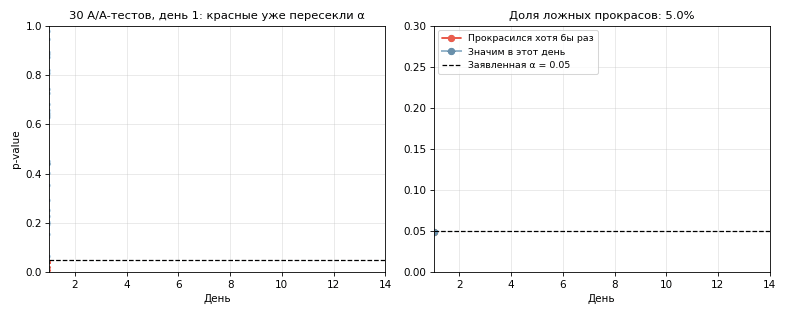

Посчитаем, как ошибка первого рода зависит от числа взглядов:

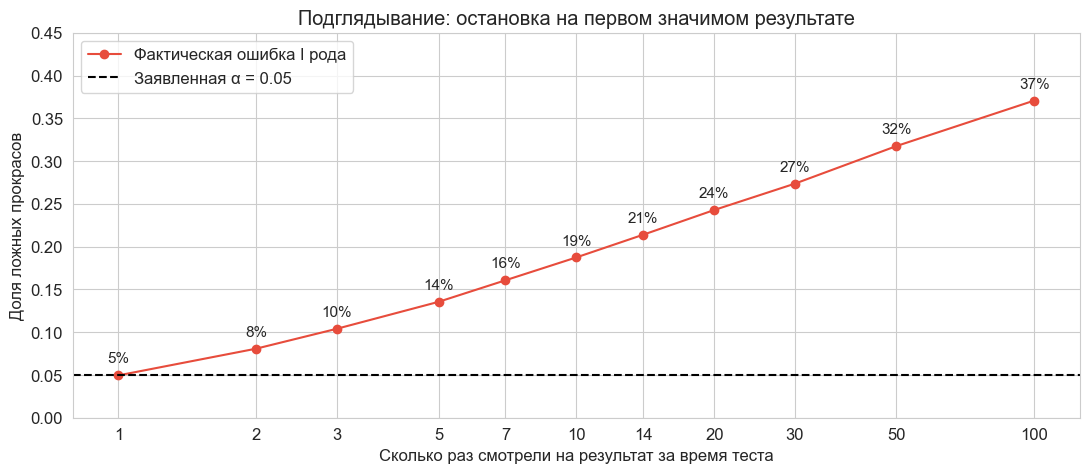

In [17]:
rng = np.random.default_rng(42)
n_tests, n_steps, alpha = 20_000, 100, 0.05

# z-статистика A/A-теста по мере накопления данных: равные порции независимых наблюдений
z_paths = rng.normal(size=(n_tests, n_steps)).cumsum(axis=1) / np.sqrt(np.arange(1, n_steps + 1))
critical_value = stats.norm.ppf(1 - alpha / 2)

n_peeks = np.array([1, 2, 3, 5, 7, 10, 14, 20, 30, 50, 100])
false_positive_rate = []
for peeks in n_peeks:
    moments = np.round(np.linspace(n_steps / peeks, n_steps, peeks)).astype(int) - 1
    false_positive_rate.append(np.mean((np.abs(z_paths[:, moments]) > critical_value).any(axis=1)))

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(n_peeks, false_positive_rate, 'o-', color='#e74c3c', label='Фактическая ошибка I рода')
ax.axhline(alpha, color='black', linestyle='--', label='Заявленная α = 0.05')
for peeks, rate in zip(n_peeks, false_positive_rate):
    ax.annotate(f'{rate:.0%}', (peeks, rate), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=11)
ax.set_xscale('log')
ax.set_xticks(n_peeks, labels=n_peeks)
ax.minorticks_off()
ax.set_ylim(0, 0.45)
ax.set_title('Подглядывание: остановка на первом значимом результате')
ax.set_xlabel('Сколько раз смотрели на результат за время теста')
ax.set_ylabel('Доля ложных прокрасов')
ax.legend()
plt.show()

При ежедневных взглядах за две недели ошибка первого рода больше чем вчетверо выше заявленной. Если смотреть на результаты всё-таки нужно, используют методы, рассчитанные на это: последовательное тестирование (занятие 2.01).

### Несоблюдение требований RCT

Вспомним ещё раз, что A/B-тест — одна из реализаций более общей методологии **Рандомизированного контролируемого испытания (RCT)**, основной смысл которой - создание **независимых** **гомогенных** групп для сравнения путём **полной рандомизации**. Соответственно, даже при правильно подобранном и точно спланированном тесте мы не сможем со статистической точки зрения гарантировать верность результатов, если у нас будут проблемы либо с рандомизацией, независимостью либо с гомогенностью групп.

С **гомогенностью** групп проблему можно попытаться решить 2 способами:
  1. Если данных достаточно, попытаться выровнять группы по ключевым показателям: исключением части пользователей или методами [мэтчинга](https://arxiv.org/pdf/1010.5586).
  2. Прибегнуть к методологиям из причинно-следственного анализа (Causal Inference), методы которого специально разработаны для таких случаев (будут рассмотрены в модуле 2).

Если ни один из методов не может быть применен, то самым правильным решением будет признание теста нерепрезентативным и перезапуск с продуманной гомогенностью.

С независимостью вопрос обстоит сложнее: в теории в любом тесте пользователи групп могут влиять друг на друга. Тем не менее, есть тесты, где эта зависимость настолько незначительна, что ей просто пренебрегают, а есть и те, где она неоспоримо вносит свой вклад (обычно это агрегаторы такси и социальные сети). В случаях с наличием зависимости обычно применяют другие подходы: switchback-тесты (занятие 2.02) или [кластерные A/B-тесты](https://medium.com/@AnalyticsAtMeta/how-meta-tests-products-with-strong-network-effects-96003a056c2c) (занятие 2.03).

С **рандомизацией** проблемы в основном возникают с технической стороны из-за двух причин:
  1. Неправильно работает сплиттер (не случайно разбиваются пользователи по группам)
  2. Есть проблемы интеграции сплиттера с продуктом (сам продукт почему-то не посылает пользователей в группу)

Первая причина возникает редко (если аналитики и разработчики неправильно реализовали назначение группы пользователю) и обычно чинится раз и навсегда.

Вторая же проблема может после починок появляться вновь, т.к. уже зависит и от продукта, который регулярно переписывается или интегрируется с новым функционалом.

Ввиду нерегулярности второго случая необходимо при проведении теста регулярно проверять, а правильно ли назначаются группы пользователям. Для этого есть 2 подхода:

**1. Sample Ratio Mismatch (SRM)**

Это проверка правильности распределения пользователей по группам. На каждый день мы кумулятивно считаем количество пользователей в каждой группе и сравниваем это распределение с запланированным, обычно с помощью $\chi^2$-теста согласия. Если критерий показывает прокрас, значит, с распределением пользователей что-то не так, и нужно оперативно разбираться.

Проверка повторяется каждый день, поэтому порог берут намного строже обычного, как правило p-value < 0.001. SRM нельзя «списать на случайность»: результаты такого теста доверия не заслуживают, пока причина не найдена.

Обычно поиски начинаются с инспекции сплиттера, чтобы убедиться, что сервис правильно назначает группы пользователей, и что проблема заложена где-то на стороне продукта.

Если проблема не со сплиттером, то начинают смотреть распределения групп в основных разрезах продукта (платформа, страна, регион, версия продукта...), чтобы локализовать проблему и найти причину неправильного разбиения.

In [18]:
# Планировали сплит 50/50, а получили такие размеры групп
observed = np.array([50_640, 49_360])
expected = observed.sum() * np.array([0.5, 0.5])
srm_p_value = stats.chisquare(observed, expected).pvalue

print(f'Разница групп: {abs(observed[0] - observed[1]) / observed.sum():.2%} от всех пользователей')
print(f'p-value SRM: {srm_p_value:.1e} -> {"есть SRM, результатам нельзя доверять" if srm_p_value < 0.001 else "SRM нет"}')

Разница групп: 1.28% от всех пользователей
p-value SRM: 5.2e-05 -> есть SRM, результатам нельзя доверять


**2. A/A/B тест**

Если же мы не хотим отдельно считать SRM, то можно пробовать проводить A/A/B тест - то есть одновременно проводить обычный A/B-тест, но ещё рядышком так же держать одну группу без воздействия, которую необходимо сравнивать с контрольной (отсюда и название A/A/B). То есть мы в тесте сравниваем две A группы между собой на отсутствие эффекта (которого нет), и только потом уже сравниваем с тестовой группой, чтобы понять наличие и размер эффекта.

В таком подходе есть 2 момента, которые необходимо понимать:

1. Из-за необходимости ввести ещё одну контрольную группу мы будем вынуждены повысить размер выборки для теста.

Если мы можем позволить увеличить размер выборки ещё на половину, то никаких проблем не возникает; если же не можем, то можно попробовать фиктивно разбить контрольную группу на 2 подгруппы, которые будем сравнивать между собой, а сравнивать тестовую группу будем уже с изначально запланированной. Такой подход может быть рабочим, если полученные подгруппы будет адекватных размеров (это требует дополнительной проверки), а так же если в механизме рандомизации не накладывается никаких дополнительных параметров на участников теста (Например все пользователи этого теста получают какой-то уникальный атрибут, из-за которого могут возникать проблемы на стороне продукта. В таком случае мы не сможем увидеть проблемы в разбиении на A/A тесте, так как обе группы имеют этот атрибут.)

2. Раз у нас есть 2 контрольных группы, то с какой из них надо же сравнивать?

Самым естественным и правильным исходом является объединение двух контрольных групп в одну со следующим сравнением с группой B. Всякие альтернативные методы (например сравнение с обоими группами или сравнение с "лучшей" контрольной группой) являются значительно хуже (если вообще правильными) естественного. Подробнее об этом написано [здесь](https://koch-kir.medium.com/не-стоит-проводить-а-а-в-тест-936e9e7a3b96).


### Итоги

1. A/B-тест — рандомизированный эксперимент: рандомизация позволяет трактовать разницу между группами как эффект изменения.
2. Дизайн фиксируется до запуска: гипотеза, метрики и их роли, критерий, $\alpha$, $\beta$, MDE, размер выборки и длительность.
3. Ошибки первого и второго рода неизбежны, но контролируемы. MDE убывает как $1/\sqrt{n}$.
4. p-value — не вероятность верности $H_0$, а незначимый результат — не доказательство отсутствия эффекта. Отчитываться лучше эффектом с доверительным интервалом.
5. Критерий выбирается под метрику и проверяется на A/A- и A/B-симуляциях. Дисперсию считаем на уровне единицы рандомизации.
6. Перед анализом проверяем SRM, а на промежуточные результаты не смотрим без специальных методов (занятие 2.01).

Посчитать всё это руками можно в практиках [1.П1](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/01.%20%D0%A6%D0%9F%D0%A2.%20%D0%94%D0%B5%D0%BB%D1%8C%D1%82%D0%B0%20%D0%BC%D0%B5%D1%82%D0%BE%D0%B4.%20%D0%9F%D0%BE%D1%81%D1%82%D1%80%D0%BE%D0%B5%D0%BD%D0%B8%D0%B5%20%D0%BE%D1%86%D0%B5%D0%BD%D0%BE%D0%BA%20%D0%B8%20%D0%B4%D0%BE%D0%B2%D0%B5%D1%80%D0%B8%D1%82%D0%B5%D0%BB%D1%8C%D0%BD%D1%8B%D1%85%20%D0%B8%D0%BD%D1%82%D0%B5%D1%80%D0%B2%D0%B0%D0%BB%D0%BE%D0%B2) и [1.П2](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/02.%20%D0%A2%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%BD%D0%BE%D0%B2%D0%BE%D0%B9%20%D1%81%D1%82%D1%80%D0%B0%D0%BD%D0%B8%D1%86%D1%8B%20%D1%87%D0%B5%D0%BA%D0%B0%D1%83%D1%82%D0%B0.%20AB%20%D1%82%D0%B5%D1%81%D1%82%20%D0%BD%D0%B0%20z%20%D1%82%D0%B5%D1%81%D1%82%D0%B5).